# Customer Segmentation Using Unsuprvised learning</p>

[customer-segmentation-target-audience-analysis-vector-isometric-illustration-audience-segmentation-i_103044-1952.webp](attachment:customer-segmentation-target-audience-analysis-vector-isometric-illustration-audience-segmentation-i_103044-1952.webp)

**In this project, I will be performing some unsupervised clustering algorithms on the sample Dataset that summarizes the usage behavior of 8950 active credit card holders during the last 6 months. Customer segmentation helps to optimize the significance of each customer to the business, Modify products according to the distinct needs and behaviors of the customers. It also helps the business to cater to the concerns of different types of customers.**

## Mount Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# <p style="background-color:#FFF9ED; font-family:newtimeroman;color:#682F2F;font-size:120%;text-align:center;border-radius:10px 10px;">Importing basic libraries</p>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# <p style="background-color:#FFF9ED; font-family:newtimeroman;color:#682F2F;font-size:120%;text-align:center;border-radius:10px 10px;">Loading dataset</p>

In [3]:
# Making data frame from csv
Data = pd.read_csv('/content/drive/MyDrive/ML/DataMining/تمرین ششم/CC GENERAL.csv')
df= pd.DataFrame(Data)
df

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,C19186,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6
8946,C19187,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.000000,6
8947,C19188,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6
8948,C19189,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6


In [4]:
print("Number of Rows : ",df.shape[0],", Number of Columns Columns : ",df.shape[1])

Number of Rows :  8950 , Number of Columns Columns :  18


# <p style="background-color:#FFF9ED; font-family:newtimeroman;color:#682F2F;font-size:120%;text-align:center;border-radius:10px 10px;">About dataset</p>

#### This case requires developing a customer segmentation to define a marketing strategy. The sample Dataset summarizes the usage behavior of 8950 active credit card holders during the last 6 months. The file is at a customer level with 18 behavioral variables.

**Columns (Features):**
- CUST_ID : Identification of Credit Card holder (Categorical)
- BALANCE : Balance amount left in their account to make purchases
- BALANCE_FREQUENCY : How frequently the Balance is updated, score between 0 and 1 (1 = frequently updated, 0 = not frequently updated)
- PURCHASES : Amount of purchases made from account
- ONEOFF_PURCHASES : Maximum purchase amount done in one-go
- INSTALLMENTS_PURCHASES : Amount of purchase done in installment
- CASH_ADVANCE : Cash in advance given by the user
- PURCHASES_FREQUENCY : How frequently the Purchases are being made, score between 0 and 1 (1 = frequently purchased, 0 = not frequently purchased)
- ONEOFF_PURCHASES_FREQUENCY : How frequently Purchases are happening in one-go (1 = frequently purchased, 0 = not frequently purchased)
- PURCHASES_INSTALLMENTS_FREQUENCY : How frequently purchases in installments are being done (1 = frequently done, 0 = not frequently done)
- CASH_ADVANCE_FREQUENCY : How frequently the cash in advance being paid
- CASH_ADVANCETRX : Number of Transactions made with "Cash in Advanced"
- PURCHASES_TRX : Numbe of purchase transactions made
- CREDIT_LIMIT : Limit of Credit Card for user
- PAYMENTS : Amount of Payment done by user
- MINIMUM_PAYMENTS : Minimum amount of payments made by user
- PRC_FULL_PAYMENT : Percent of full payment paid by user
- TENURE : Tenure of credit card service for user

> **Target ==>>> We want to set Clusters**

# EDA and PREPROCESSING

In [5]:
df.columns
df.columns.tolist()

['CUST_ID',
 'BALANCE',
 'BALANCE_FREQUENCY',
 'PURCHASES',
 'ONEOFF_PURCHASES',
 'INSTALLMENTS_PURCHASES',
 'CASH_ADVANCE',
 'PURCHASES_FREQUENCY',
 'ONEOFF_PURCHASES_FREQUENCY',
 'PURCHASES_INSTALLMENTS_FREQUENCY',
 'CASH_ADVANCE_FREQUENCY',
 'CASH_ADVANCE_TRX',
 'PURCHASES_TRX',
 'CREDIT_LIMIT',
 'PAYMENTS',
 'MINIMUM_PAYMENTS',
 'PRC_FULL_PAYMENT',
 'TENURE']

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [7]:
df.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


### Searching for missing values

In [8]:
df.isnull().sum()
print('----------------------------------------\n Percentage of missing data: \n')
print((df[['MINIMUM_PAYMENTS', 'CREDIT_LIMIT']].isnull().sum()/df['CUST_ID'].count())*100)

----------------------------------------
 Percentage of missing data: 

MINIMUM_PAYMENTS    3.497207
CREDIT_LIMIT        0.011173
dtype: float64


In [9]:
# Finding unique values in columns to determine if there is any missing values including (-,?...)
df.loc[df.index.isin(['?','-'])].value_counts()

,,,,,,,,,,,,,,,,,,count
CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,


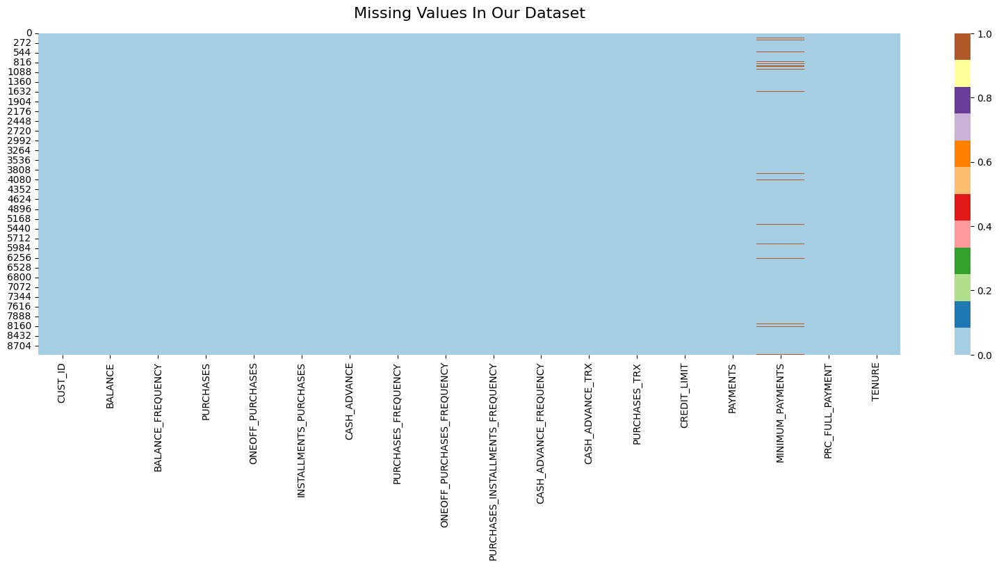

In [10]:
plt.figure(figsize = (20,6))
sns.heatmap(df.isnull(), cmap="Paired", fmt='d')
plt.title('Missing Values In Our Dataset',fontsize=16, color = 'black', y=1.03)
plt.show()

#### Customer ID seems to be an unique id for each customer and hence won't play any role in determining the cluster, so we drop it.

In [11]:
df.drop('CUST_ID', axis=1, inplace = True)

### Searching for duplicate values

In [12]:
print(f"Number of dublicated: {df.duplicated().sum()}")
print(f"number of rows: {df.shape}")
print(f"number of duplicate rows: {df[df.duplicated()].shape}")

Number of dublicated: 0
number of rows: (8950, 17)
number of duplicate rows: (0, 17)


## Bivariate Analysis

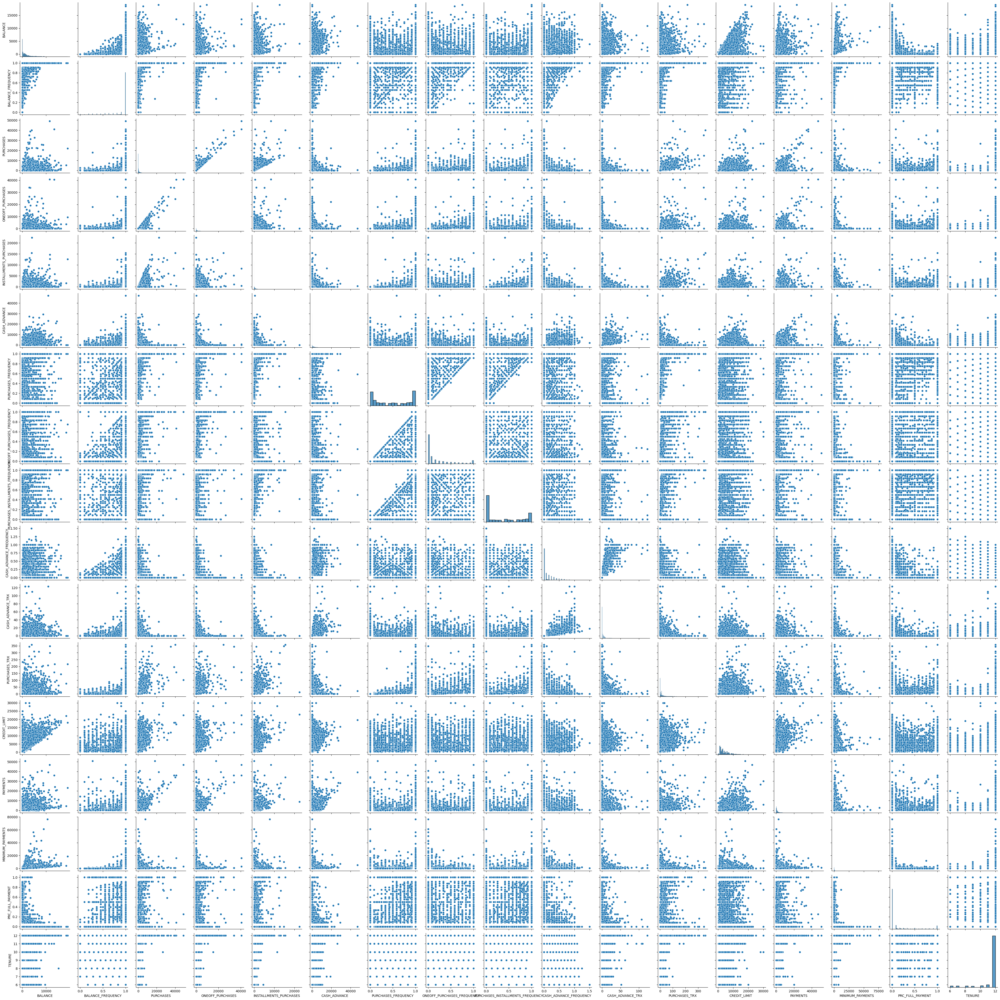

In [13]:
sns.pairplot(df)

**We see from the plots:**
- As the credit limit increase, the balance also increases hence a linear relationship.
- As the number of purchases increases, the number of "cash in advance" transactions decreases.
- As the credit balance is low, the purchases, one-off purchases, and installment purchases are less.
- As the credit balance is low, the "cash in advance" transactions are less.
- Purchases, one-off purchases, and installment purchases are all related linearly.

## Correlation

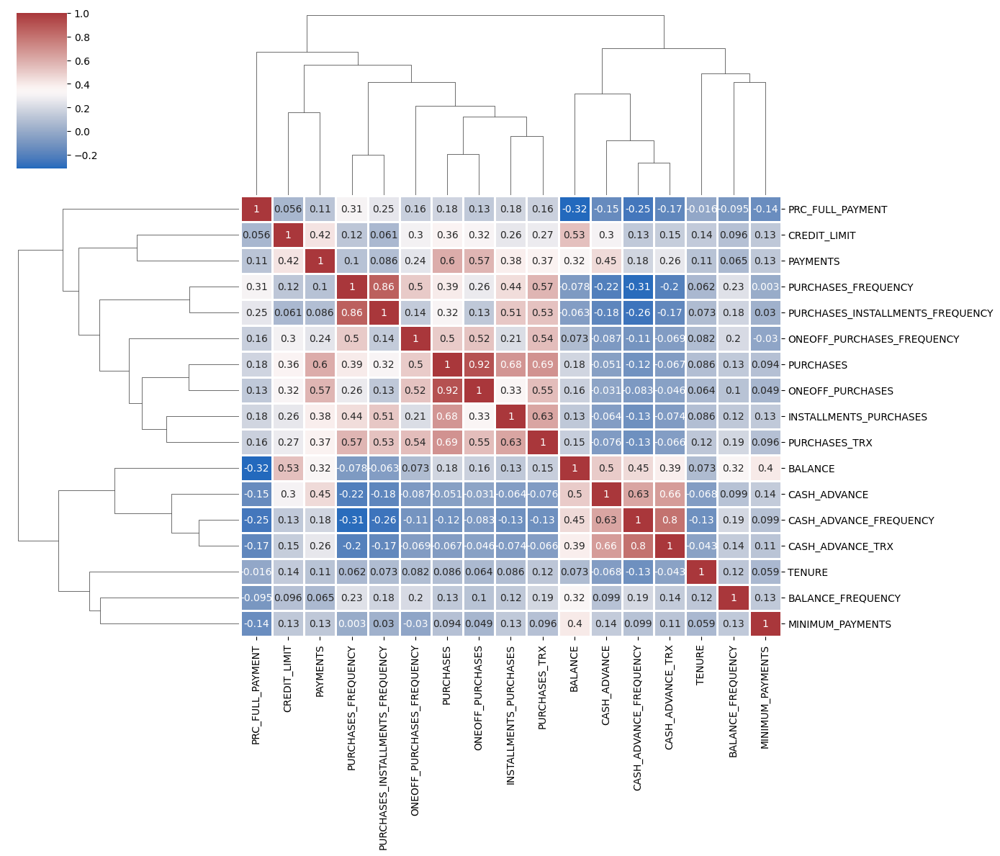

In [14]:
sns.clustermap(df.corr(), cmap = "vlag", dendrogram_ratio = (0.3, 0.3), annot = True, linewidths = .8, figsize = (14,12))
plt.show()

**We see from the heatmap:**

**<span style="color:#682F2F;">> We've got some pair of features with high correlation that might not be a good thing for modeling: </span>**

- ONEOFF_PURCHASES and PURCHASES have the highest correlation (92%) between other features.
- PURCHASE_FREQUENCY and PURCHASES_INSTALLMENTS_FREQUENCY also have a high correlation (86%).
- CASH_ADVANCE_FREQUENCY and CASH_ADVANCE_TRX also have a high correlation (80%).
- People do not make full payments when the balance is high.
- Purchase frequency and cash advance frequency are inversely correlated. That is as the purchase frequency is high, the number of times cash is paid in advance is less and vice-versa.
- Inspecting all the plots above, a good feature to be used as the key feature for plotting and comparison purporses, is BALANCE. Reasons for this choice is that this feature is not discrete. Also, based on the distplot, values of this feature are more varied in comparison with other continuous features. In addition, this column is correlated with others to a good extent.

## Univariate Analysis

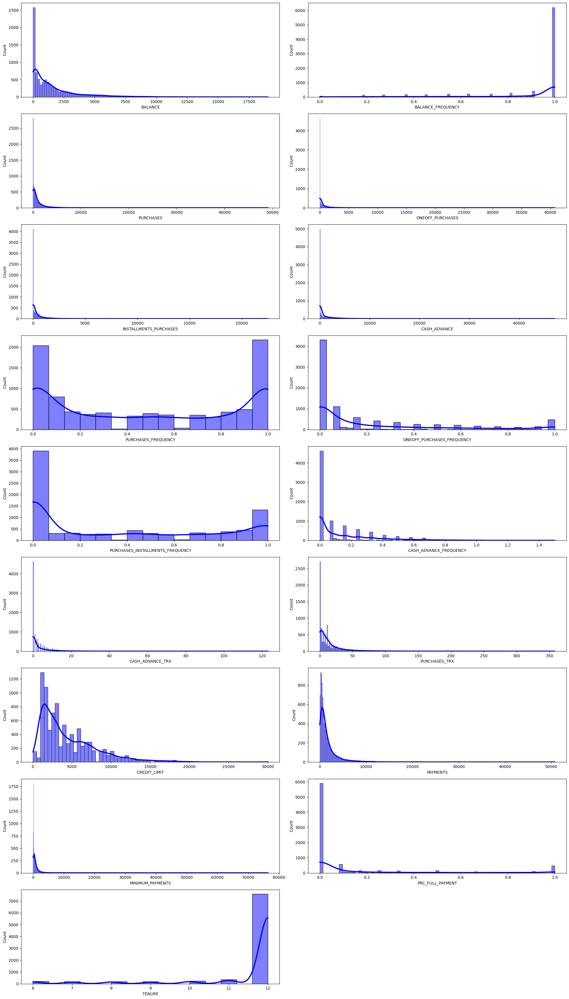

In [15]:
plt.figure(figsize=(20, 35))

for i, col in enumerate(df.columns):
    ax = plt.subplot(9, 2, i + 1)
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        line_kws={"color": "orange", "lw": 3},
        color="blue",
        ax=ax
    )
    plt.xlabel(col)
plt.tight_layout()
plt.show()

**We see from the plots:**
- Most credit card holders have a low credit limit and maintain credit balances below 7500.
- Variables such as Purchases, OneOffPurchases, installment purchases, and cash advances also follow the same trend as a credit balance. They could all be related. That is as the credit balance is low, the purchases are also low, and so on.
- Most people either don't purchase anything or purchase very frequently.
- People who purchase in installments are more than people who purchase in one go.
- In the last 6 months, most people have made total payments below 10000, with the minimum payments below 5000.
- Finally, most of credit card holders own a card for more than 12 months.

In [16]:
df.skew()

,0
BALANCE,2.393386
BALANCE_FREQUENCY,-2.023266
PURCHASES,8.144269
ONEOFF_PURCHASES,10.045083
INSTALLMENTS_PURCHASES,7.299120
CASH_ADVANCE,5.166609
PURCHASES_FREQUENCY,0.060164
ONEOFF_PURCHASES_FREQUENCY,1.535613
PURCHASES_INSTALLMENTS_FREQUENCY,0.509201
CASH_ADVANCE_FREQUENCY,1.828686


#### ✅ There is a lot of skewness and they are varied. It is kind of expected from datasets like these as there will always be a few customers who do a very high amounts of transactions.

## Searching for outliers

#### Outlier is an observation in a given dataset that lies far from the rest of the observations. That means an outlier is vastly larger or smaller than the remaining values in the set

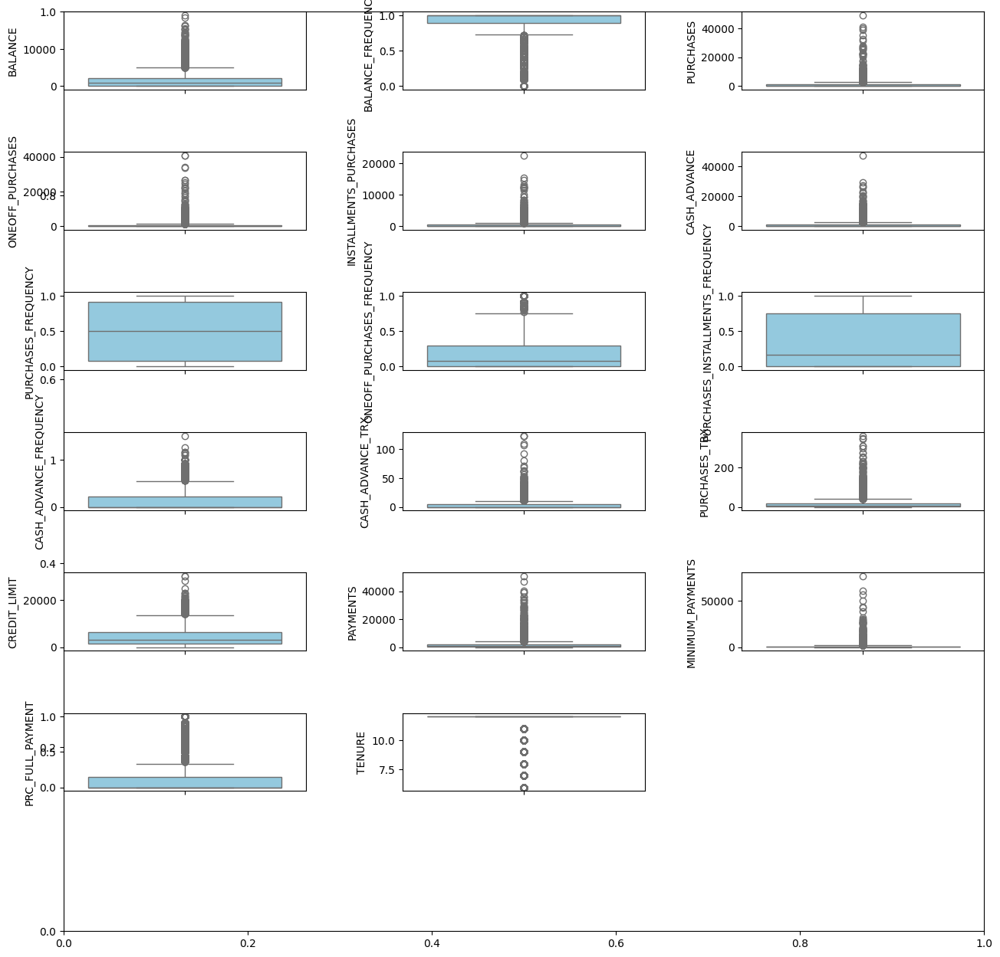

In [17]:
plt.subplots(figsize=(15, 15))
plt.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=0.9, wspace=0.4, hspace=0.8)

for i, column in enumerate(df.columns, 1):
    plt.subplot(7, 3, i)
    sns.boxplot(df[column], color='skyblue')

In [18]:
# Detecting outliers using the Inter Quantile Range(IQR)
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
#calc Lower bound and upper bound
LB = Q1 - 1.5 * IQR
UB = Q3 + 1.5 * IQR
# check if value bigger than upper bound, or smaller than Lower bound
No_Outliers = df[(df < LB) | (df > UB)].count()
print('Number of Outliers at each column:\n')
print('-'*50)
DF_outlier = pd.DataFrame(No_Outliers, columns=['(No. Outliers)'])
# To show whole rows
pd.set_option('display.max_rows', DF_outlier.shape[0]+1)
print(DF_outlier)

Number of Outliers at each column:

--------------------------------------------------
                                  (No. Outliers)
BALANCE                                      695
BALANCE_FREQUENCY                           1493
PURCHASES                                    808
ONEOFF_PURCHASES                            1013
INSTALLMENTS_PURCHASES                       867
CASH_ADVANCE                                1030
PURCHASES_FREQUENCY                            0
ONEOFF_PURCHASES_FREQUENCY                   782
PURCHASES_INSTALLMENTS_FREQUENCY               0
CASH_ADVANCE_FREQUENCY                       525
CASH_ADVANCE_TRX                             804
PURCHASES_TRX                                766
CREDIT_LIMIT                                 248
PAYMENTS                                     808
MINIMUM_PAYMENTS                             841
PRC_FULL_PAYMENT                            1474
TENURE                                      1366


In [19]:
#Dropping the outliers
df = df[(df['CASH_ADVANCE']<40000)]
df = df[(df['INSTALLMENTS_PURCHASES']<20000)]
print("The total number of data-points after removing the outliers are:", len(df))

The total number of data-points after removing the outliers are: 8948


#### ✅ We observe a lot of outliers here, hence deleting these outliers is not recommended. we will avoid deleting the outlier records. Data transformations must be applied very cautiously as the results of standard statistical tests performed on log-transformed data are often not relevant for the original, non-transformed data. But you can normalize the data and handle the skewness using log transformation or power transformers if you want to.

## Dealing with missing values

In [20]:
# missing values in 'CREDIT_LIMIT' column
Nulls_value = pd.isnull(df["CREDIT_LIMIT"])
df[Nulls_value]

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
5203,18.400472,0.166667,0.0,0.0,0.0,186.853063,0.0,0.0,0.0,0.166667,1,0,NaN,9.040017,14.418723,0.0,6


#### We have seen that credit limit feature has just 0.01% of records having Nan value i.e just 1 record here has missing value. So we don't have to take the trouble to impute it. We can simply drop it.

In [21]:
df.drop([5203], axis=0, inplace=True)
df.reset_index( inplace = True)
df.drop('index',axis=1,inplace = True)
df

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8942,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6
8943,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.000000,6
8944,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6
8945,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6


In [22]:
# missing values in 'MINIMUM_PAYMENTS' column
Nulls_val = pd.isnull(df["MINIMUM_PAYMENTS"])
df[Nulls_val]

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
3,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.0,12
45,2242.311686,1.000000,437.00,97.00,340.0,184.648692,0.333333,0.083333,0.333333,0.166667,2,5,2400.0,0.000000,NaN,0.0,12
47,3910.111237,1.000000,0.00,0.00,0.0,1980.873201,0.000000,0.000000,0.000000,0.500000,7,0,4200.0,0.000000,NaN,0.0,12
54,6.660517,0.636364,310.00,0.00,310.0,0.000000,0.666667,0.000000,0.666667,0.000000,0,8,1000.0,417.016763,NaN,0.0,12
55,1311.995984,1.000000,1283.90,1283.90,0.0,0.000000,0.250000,0.250000,0.000000,0.000000,0,6,6000.0,0.000000,NaN,0.0,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8916,14.524779,0.333333,152.00,152.00,0.0,0.000000,0.333333,0.333333,0.000000,0.000000,0,2,1500.0,0.000000,NaN,0.0,6
8926,371.527312,0.333333,0.00,0.00,0.0,1465.407927,0.000000,0.000000,0.000000,0.166667,5,0,1500.0,0.000000,NaN,0.0,6
8932,183.817004,1.000000,465.90,0.00,465.9,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1500.0,0.000000,NaN,0.0,6
8941,193.571722,0.833333,1012.73,1012.73,0.0,0.000000,0.333333,0.333333,0.000000,0.000000,0,2,4000.0,0.000000,NaN,0.0,6


#### For imputing minimum payments feature, I don't see any column which has relation with this feature and help us estimate values for missing records. It seems that the values are missing at random and we can simply use median to replace the Nan values as the distribution for minimum payments is skewed and hence median gives a better estimation of the central tendency of this feature.

In [23]:
df['MINIMUM_PAYMENTS'] = df['MINIMUM_PAYMENTS'].fillna(df['MINIMUM_PAYMENTS'].median())

In [24]:
print("Number of Rows : ",df.shape[0],", Number of Columns : ",df.shape[1])

Number of Rows :  8947 , Number of Columns :  17


In [25]:
df.isnull().sum()

,0
BALANCE,0
BALANCE_FREQUENCY,0
PURCHASES,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES_FREQUENCY,0
PURCHASES_INSTALLMENTS_FREQUENCY,0
CASH_ADVANCE_FREQUENCY,0


# <p style="background-color:#682F2F;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Data Standardization</p>

### Normalizing the data is important to ensure that the distance measure accords equal weight to each variable. Without normalization, the variable with the largest scale will dominate the measure. Also raw data might have some bias problems, when we normalize the data it is fixed.

In [26]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(df)
scaled_df = pd.DataFrame(scaler.transform(df), columns = df.columns)
scaled_df

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-0.732220,-0.249876,-0.426211,-0.356991,-0.358518,-0.477456,-0.806533,-0.678717,-0.707283,-0.675534,-0.482502,-0.511310,-0.961559,-0.532398,-0.302200,-0.525663,0.360587
1,0.788357,0.134026,-0.471111,-0.356991,-0.467702,2.681176,-1.221767,-0.678717,-0.916941,0.574907,0.113905,-0.591761,0.691223,0.828166,0.097723,0.234022,0.360587
2,0.448167,0.517929,-0.107218,0.108762,-0.467702,-0.477456,1.269632,2.673010,-0.916941,-0.675534,-0.482502,-0.109054,0.828955,-0.385830,-0.093081,-0.525663,0.360587
3,0.049705,-1.017680,0.234394,0.545997,-0.467702,-0.376569,-1.014151,-0.399407,-0.916941,-0.258722,-0.333400,-0.551535,0.828955,-0.602777,-0.228140,-0.525663,0.360587
4,-0.358606,0.517929,-0.463581,-0.347353,-0.467702,-0.477456,-1.014151,-0.399407,-0.916941,-0.675534,-0.482502,-0.551535,-0.906466,-0.366206,-0.257064,-0.525663,0.360587
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8942,-0.738187,0.517929,-0.334095,-0.356991,-0.134520,-0.477456,1.269632,-0.678717,1.179649,-0.675534,-0.482502,-0.350408,-0.961559,-0.489225,-0.341052,1.183631,-4.126437
8943,-0.742665,0.517929,-0.329916,-0.356991,-0.124357,-0.477456,1.269632,-0.678717,1.179649,-0.675534,-0.482502,-0.350408,-0.961559,-0.506570,-0.228140,-0.525663,-4.126437
8944,-0.740638,-0.185894,-0.403149,-0.356991,-0.302438,-0.477456,0.854398,-0.678717,0.760333,-0.675534,-0.482502,-0.390633,-0.961559,-0.574434,-0.326676,0.328984,-4.126437
8945,-0.745419,-0.185894,-0.471111,-0.356991,-0.467702,-0.459533,-1.221767,-0.678717,-0.916941,0.158095,-0.184298,-0.591761,-1.099291,-0.584450,-0.338107,0.328984,-4.126437


# Models

## <p style="background-color:#682F2F;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">Clustering  Algorithms</p>

### Clustering is an unsupervised learning problem. When you don’t have a training dataset, you need to group your data for specific situations such as outlier or not, healthy or sick, etc.

### <p style="background-color:#682F2F;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;"> 1. K-means algorithm</p>

**K-means clustering algorithm is one of the most known clustering algorithms. by using it we group similar data points together and discover underlying patterns.  With K-means, we should select how many clusters you will use. After that samples will be selected randomly to center the clusters, and then performs iterative (repetitive) calculations to optimize the positions of the centroids It halts creating and optimizing clusters when either: The centroids have stabilized — there is no change in their values because the clustering has been successful.**

In [27]:
kmean_set = {'init':'random', 'n_init':10, 'max_iter':300, 'random_state':1}

from sklearn.cluster import KMeans
List = []
for k in range(1, 11):   #this range is optional
    kmeans = KMeans(n_clusters=k, **kmean_set )  # ** Open dic
    kmeans.fit(scaled_df)
    List.append(kmeans.inertia_)

In [28]:
print('List of interia: ', List)

List of interia:  [152099.00000000067, 127602.64357859404, 111572.60963126711, 98650.8557080234, 91137.72986018457, 84478.14654534918, 79135.75391662809, 73970.35468686777, 70638.37183359216, 66042.35037700585]


### >> The Elbow method

#### The KElbowVisualizer implements the “elbow” method to help data scientists select the optimal number of clusters by fitting the model with a range of values for . If the line chart resembles an arm, then the “elbow” (the point of inflection on the curve) is a good indication that the underlying model fits best at that point. In the visualizer “elbow” will be annotated with a dashed line.

In [29]:
!pip install kneed
# pip install kneed or conda install kneed

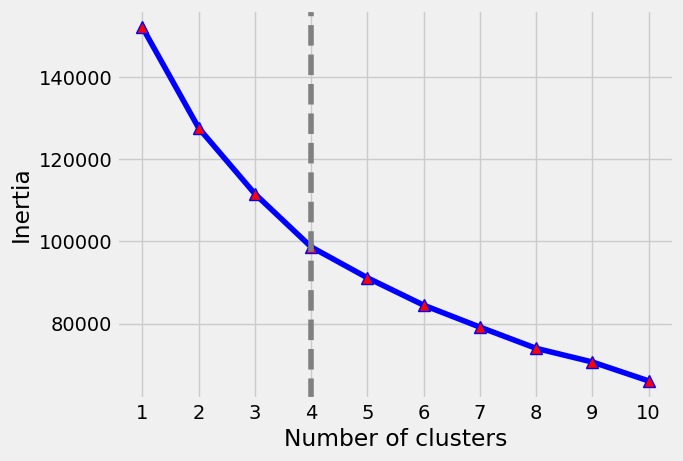

In [30]:
from kneed import KneeLocator, DataGenerator
kl = KneeLocator(range(1, 11), List, curve = 'convex', direction = 'decreasing')
kl.elbow

plt.style.use('fivethirtyeight')
plt.plot(range(1, 11), List, marker = '^', c='b',  ms = 9, mfc = 'r')
plt.xticks(range(1, 11))
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.axvline(x=kl.elbow, color ='gray', label = 'axvline - full height', ls = '--')

plt.show()

## Model Evaluation

### >> Silhouette Coefficient
**Silhouette Coefficient or silhouette score is a metric used to calculate the goodness of a clustering technique. Its value ranges from -1 to 1.**

* 1: Means clusters are well apart from each other and clearly distinguished.

* 0: Means clusters are indifferent, or we can say that the distance between clusters is not significant.

* -1: Means clusters are assigned in the wrong way.

In [31]:
from sklearn.metrics import silhouette_score
silhouette_coefficients = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, **kmean_set )
    kmeans.fit(scaled_df)
    score = silhouette_score(scaled_df, kmeans.labels_)
    silhouette_coefficients.append(score)

In [32]:
print('silhouette_coefficients: ', silhouette_coefficients)

silhouette_coefficients:  [np.float64(0.2099525412520319), np.float64(0.25069358856132073), np.float64(0.197834068302401), np.float64(0.192515355612675), np.float64(0.20199461968362195), np.float64(0.2081968707185711), np.float64(0.221070660118742), np.float64(0.21414022410269867), np.float64(0.21900787116362563)]


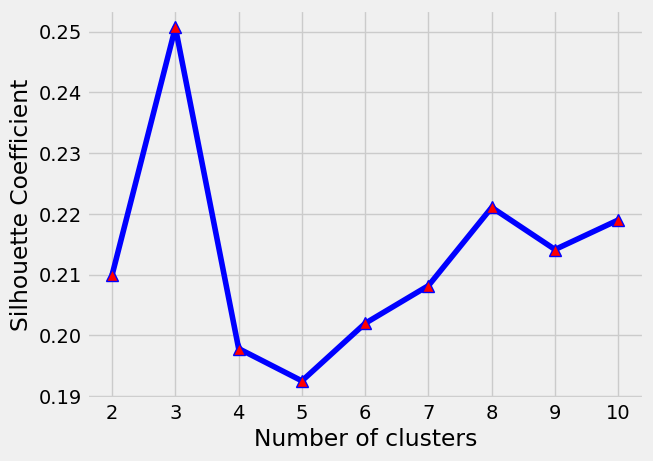

In [33]:
plt.style.use('fivethirtyeight')
plt.plot(range(2, 11), silhouette_coefficients, marker = '^', c = 'b', ms = 9, mfc = 'r')
plt.xticks(range(2, 11))
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Coefficient')
plt.show()

### >> Calinski_Harabasz Coefficient
#### The Calinski-Harabasz index (CH) is one of the clustering algorithms evaluation measures. It is most commonly used to evaluate the goodness of split by a K-Means clustering algorithm for a given number of clusters. The Calinski-Harabasz index (also known as the Variance Ratio Criterion) is calculated as a ratio of the sum of inter-cluster dispersion and the sum of intra-cluster dispersion for all clusters (where the dispersion is the sum of squared distances).
#### A high CH means better clustering since observations in each cluster are closer together (more dense), while clusters themselves are further away from each other (well separated).

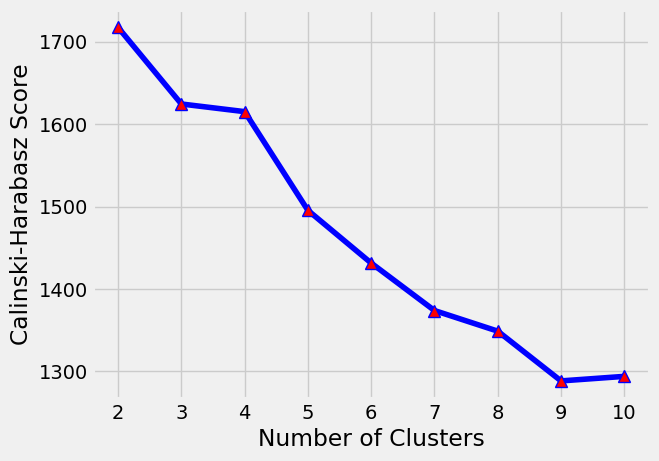

calinski_harabaz:  [np.float64(1717.2114677572129), np.float64(1624.360699180715), np.float64(1615.0794904260008), np.float64(1495.3077842630266), np.float64(1431.373042570479), np.float64(1373.7941519093092), np.float64(1348.790941079768), np.float64(1288.4199402744214), np.float64(1293.9311303703394)]


In [34]:
from sklearn import metrics
from sklearn.metrics import calinski_harabasz_score

calinski_harabaz = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, **kmean_set)
    kmeans.fit(scaled_df)

    score = calinski_harabasz_score(scaled_df, kmeans.labels_)
    calinski_harabaz.append(score)

plt.style.use("fivethirtyeight")
plt.plot(range(2, 11), calinski_harabaz, marker='^', c='b', ms=9, mfc='r')
plt.xticks(range(2, 11))
plt.xlabel("Number of Clusters")
plt.ylabel("Calinski-Harabasz Score")
plt.show()

print('calinski_harabaz: ', calinski_harabaz)


In [35]:
print('calinski_harabaz: ', calinski_harabaz)

calinski_harabaz:  [np.float64(1717.2114677572129), np.float64(1624.360699180715), np.float64(1615.0794904260008), np.float64(1495.3077842630266), np.float64(1431.373042570479), np.float64(1373.7941519093092), np.float64(1348.790941079768), np.float64(1288.4199402744214), np.float64(1293.9311303703394)]


Based on the Silhouette Coefficient, 3 clusters achieve the highest score. However, the Calinski-Harabasz score is highest at 2 clusters, so 3 clusters will be considered a candidate for further analysis.

## Apply the k-means

In [36]:
kmeans = KMeans(n_clusters=3, **kmean_set )
kmeans.fit(scaled_df)
labels = kmeans.labels_

In [37]:
# cluster centers (normalized centers, here ther are negative values)
cluster_centers = pd.DataFrame(data = kmeans.cluster_centers_, columns = [df.columns])
cluster_centers

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-0.366813,-0.177398,-0.232890,-0.203511,-0.179647,-0.317497,-0.061760,-0.232881,-0.048602,-0.335556,-0.303117,-0.243243,-0.335958,-0.285893,-0.135025,0.006931,-0.027824
1,0.320832,0.439956,1.531774,1.277398,1.298118,-0.250390,1.143709,1.551969,0.963320,-0.356383,-0.252083,1.682970,0.891358,0.846323,0.173945,0.496580,0.303014
2,1.155916,0.339101,-0.291670,-0.207661,-0.314978,1.408309,-0.646856,-0.307298,-0.557906,1.559262,1.354586,-0.368809,0.597276,0.440469,0.382371,-0.409991,-0.127520


In [38]:
# real cluster centers (now ther are no negative values)
cluster_centers = scaler.inverse_transform(cluster_centers)
cluster_centers = pd.DataFrame(data = cluster_centers, columns = [df.columns])
cluster_centers

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,800.651456,0.835345,506.153377,254.784911,251.689473,326.281989,0.465605,0.133017,0.345139,0.067972,1.203107,8.664105,3271.083170,908.623257,529.449821,0.155794,11.480621
1,2230.395466,0.981536,4255.565316,2713.155843,1542.895697,463.166963,0.949457,0.665533,0.747349,0.063808,1.545381,56.549433,7726.539708,4155.095433,1250.129510,0.299025,11.923015
2,3966.692043,0.957653,381.261471,247.895451,133.443411,3846.564453,0.230758,0.110814,0.142706,0.446801,12.321026,5.542553,6658.951530,2991.364202,1736.288057,0.033836,11.347309


#### We add cluster column to dataframe

In [39]:
df_cluster_with_kmean = pd.concat([df, pd.DataFrame({'cluster': labels})], axis = 1)
df_cluster_with_kmean

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,cluster
0,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12,0
1,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12,2
2,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12,0
3,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,312.255623,0.000000,12,0
4,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8942,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6,0
8943,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,312.255623,0.000000,6,0
8944,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6,0
8945,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6,0


### let us have a look at the group distribution of clustring

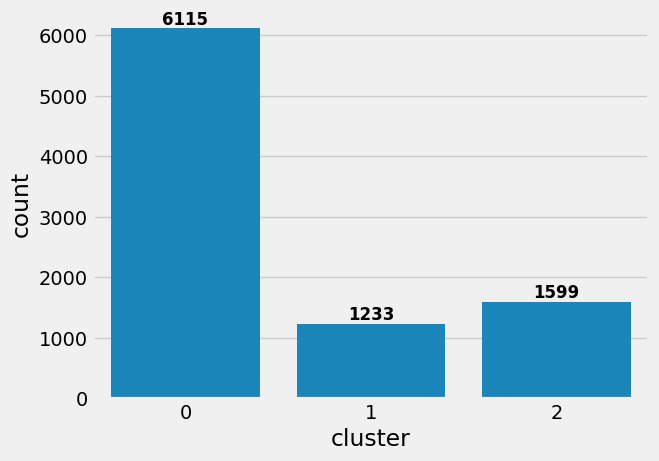

In [40]:
ax = sns.countplot(x=df_cluster_with_kmean.cluster)
ax.bar_label(ax.containers[0], fontsize=12, color='black', fontweight='bold')
plt.show()

#### most of people are grouped in cluster 0

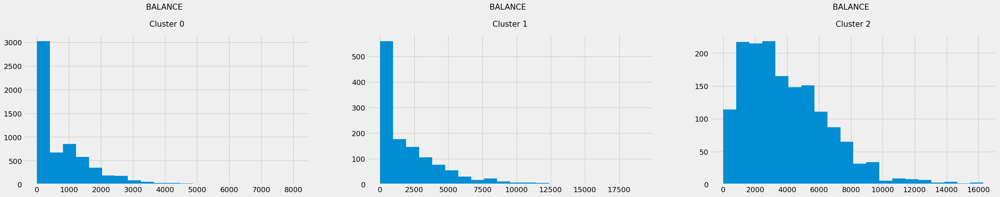

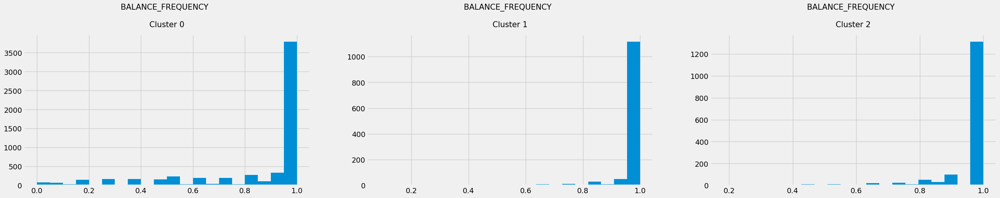

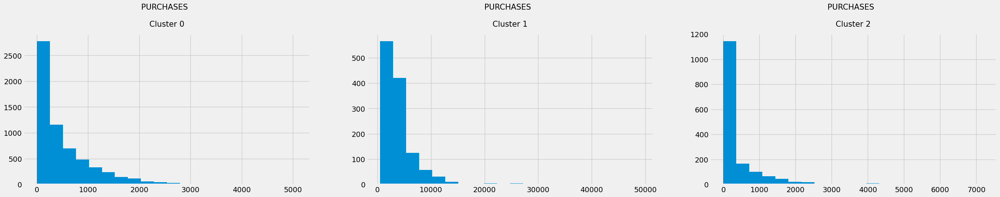

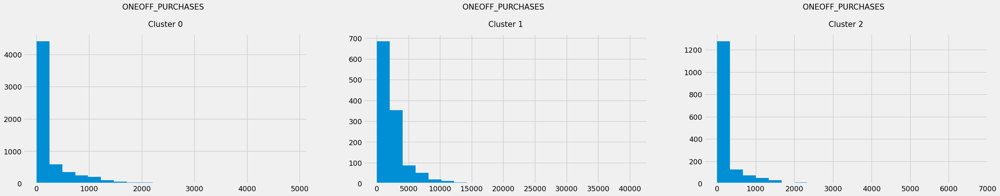

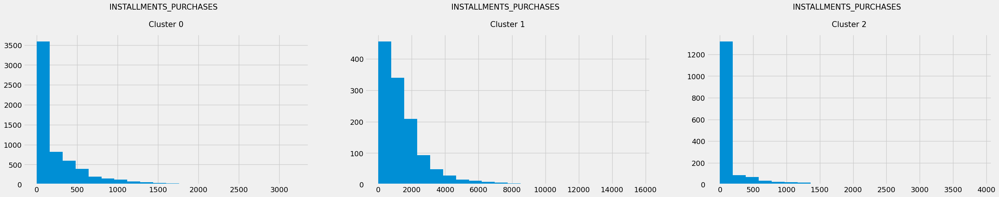

...

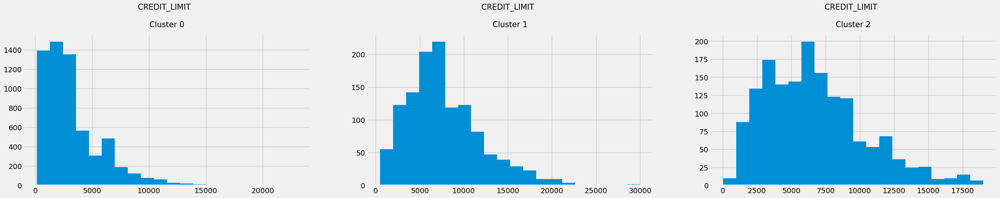

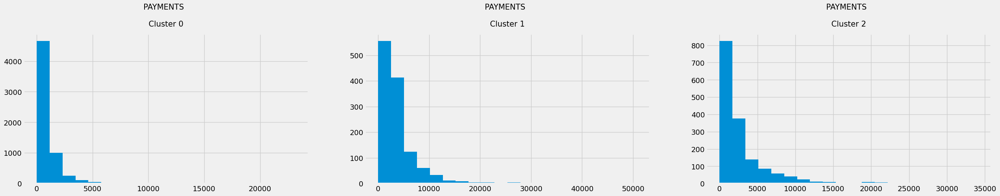

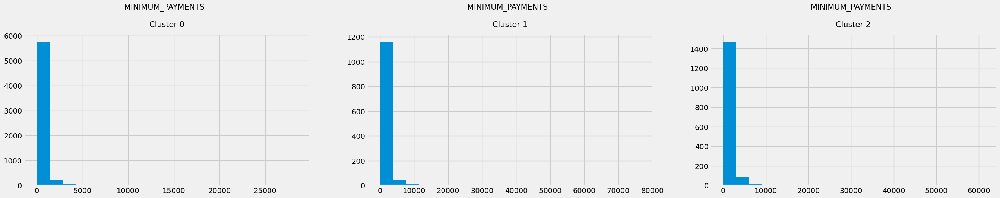

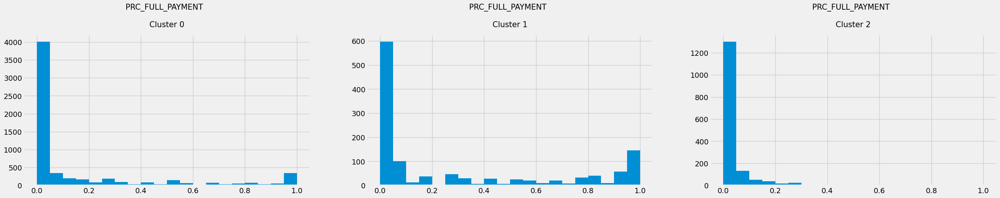

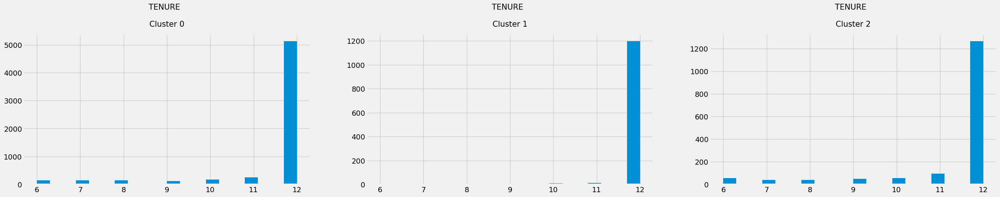

In [41]:
# Plot the histogram of various clusters
for i in df.columns:
    plt.figure(figsize=(30,5))
    for j in range(3):
        plt.subplot(1,3,j+1)
        cluster = df_cluster_with_kmean[df_cluster_with_kmean['cluster'] == j]
        cluster[i].hist(bins = 20)
        plt.title('{}  \n\nCluster {}'.format(i,j), color='black', fontsize = 15, y=1.03)

plt.show()

* Cluster0: People with low to average credit limit who make all type of purchases.

* Cluster1: Less money spenders with average to high credit limits who purchases mostly in installments.

* Cluster2: People with high credit limit who take more cash in advance.

## visualizing clusters on original data

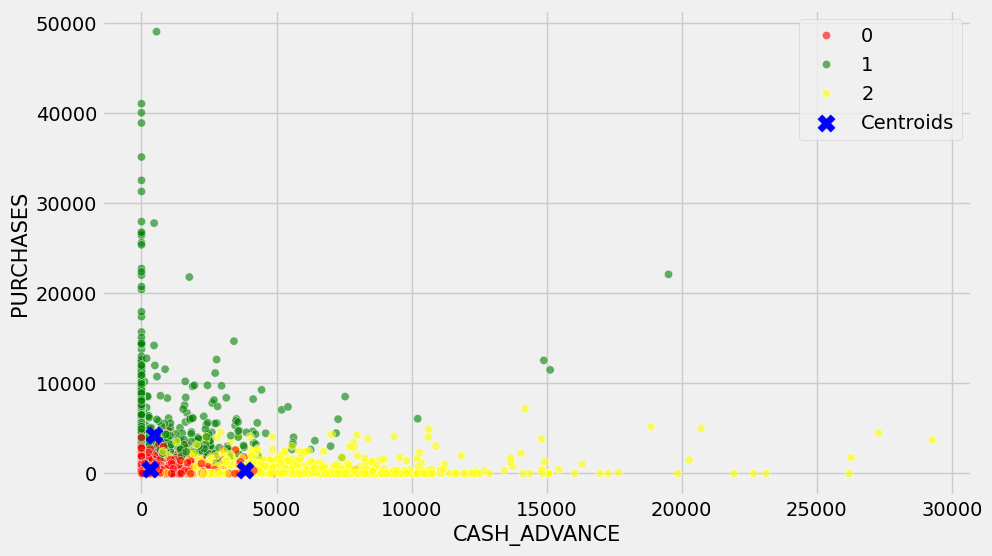

In [42]:
# Visualizing clusters on original data

df_kmean = df.copy()
df_kmean['cluster'] = labels

# Convert the scaled cluster centers to the original scale
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

x_col = 'CASH_ADVANCE'
y_col = 'PURCHASES'

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_kmean,
    x=x_col,
    y=y_col,
    hue='cluster',
    palette=['red', 'green', 'yellow'],
    alpha=0.6
)

plt.scatter(
    centroids[:, df.columns.get_loc(x_col)],
    centroids[:, df.columns.get_loc(y_col)],
    c='blue',
    marker='X',
    s=150,
    label='Centroids'
)

plt.xlabel(x_col, fontsize=15)
plt.ylabel(y_col, fontsize=15)
plt.legend()
plt.show()


### 3D projection of 3 generated clusters

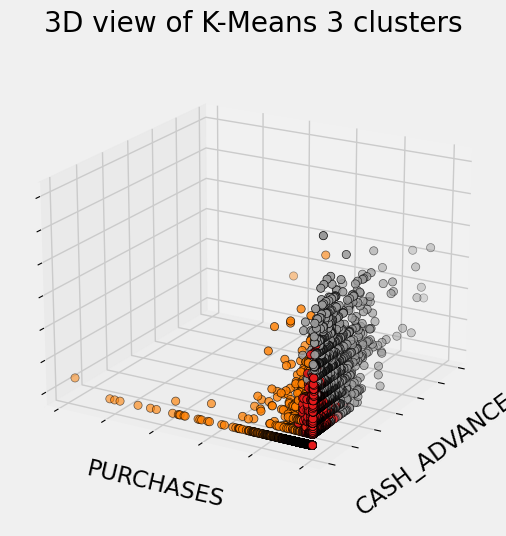

In [43]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection='3d')
ax.view_init(elev=20, azim=210)

ax.scatter(df_kmean['CASH_ADVANCE'],
           df_kmean['PURCHASES'],
           df_kmean['CASH_ADVANCE_FREQUENCY'],
           c=df_kmean['cluster'],
           s=35, edgecolor='k', cmap=plt.cm.Set1)

ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_zticklabels([])

ax.set_xlabel('CASH_ADVANCE')
ax.set_ylabel('PURCHASES')
ax.set_zlabel('CASH_ADVANCE_FREQUENCY')
ax.set_title('3D view of K-Means 3 clusters')
ax.dist = 12

plt.show()

### 3D Plotly version

In [44]:
import plotly as py
import plotly.graph_objs as go

def tracer(db, n, name):
    '''
    This function returns trace object for Plotly
    '''
    return go.Scatter3d(
        x = db[db['cluster']==n]['CASH_ADVANCE'],
        y = db[db['cluster']==n]['PURCHASES'],
        z = db[db['cluster']==n]['CASH_ADVANCE_FREQUENCY'],
        mode = 'markers',
        name = name,
        marker = dict(
            size = 4
        )
     )

trace0 = tracer(df_kmean, 0, 'Cluster 0')
trace1 = tracer(df_kmean, 1, 'Cluster 1')
trace2 = tracer(df_kmean, 2, 'Cluster 2')

data = [trace0, trace1, trace2]

layout = go.Layout(
    title = 'Clusters by K-Means',
    scene = dict(
            xaxis = dict(title = 'CASH_ADVANCE'),
            yaxis = dict(title = 'PURCHASES'),
            zaxis = dict(title = 'CASH_ADVANCE_FREQUENCY')
        )
)

fig = go.Figure(data=data, layout=layout)
py.offline.iplot(fig)

### To plot selected features with clusters obtained from scaled data

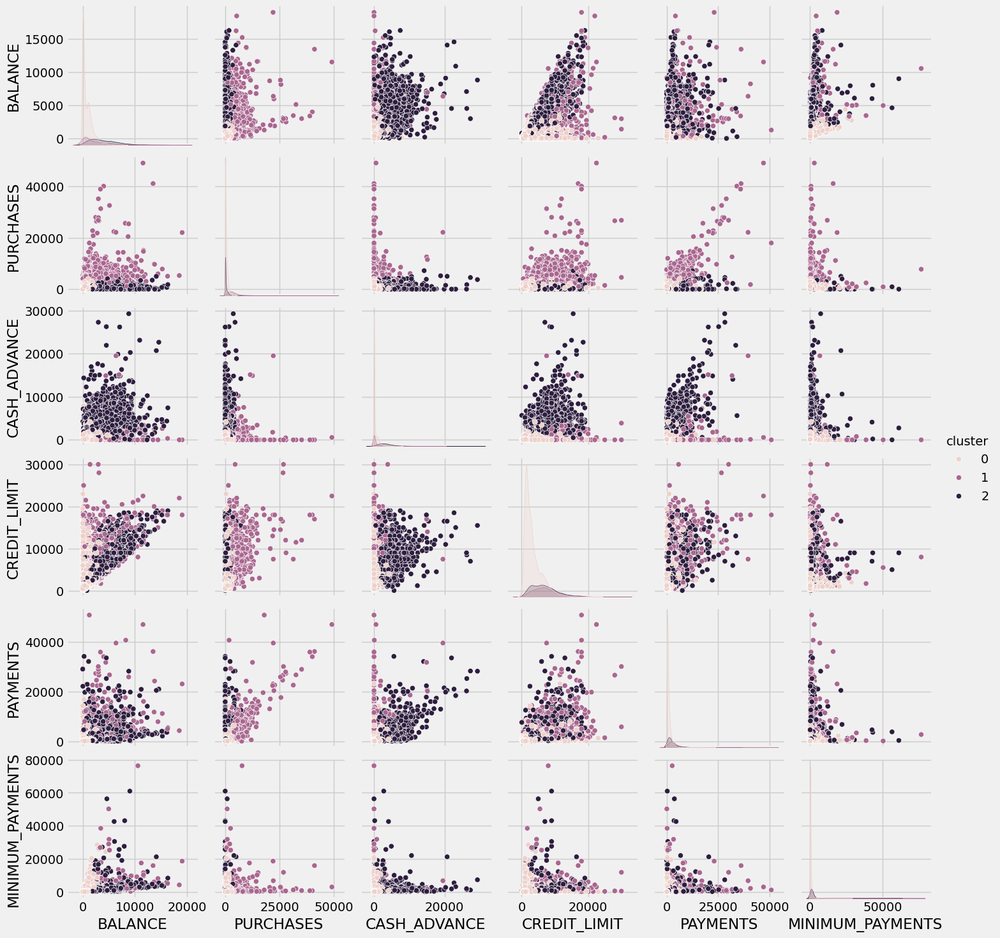

In [45]:
best_cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE","CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS","cluster"]
sns.pairplot( df_cluster_with_kmean[ best_cols ], hue="cluster")

### To plot original features

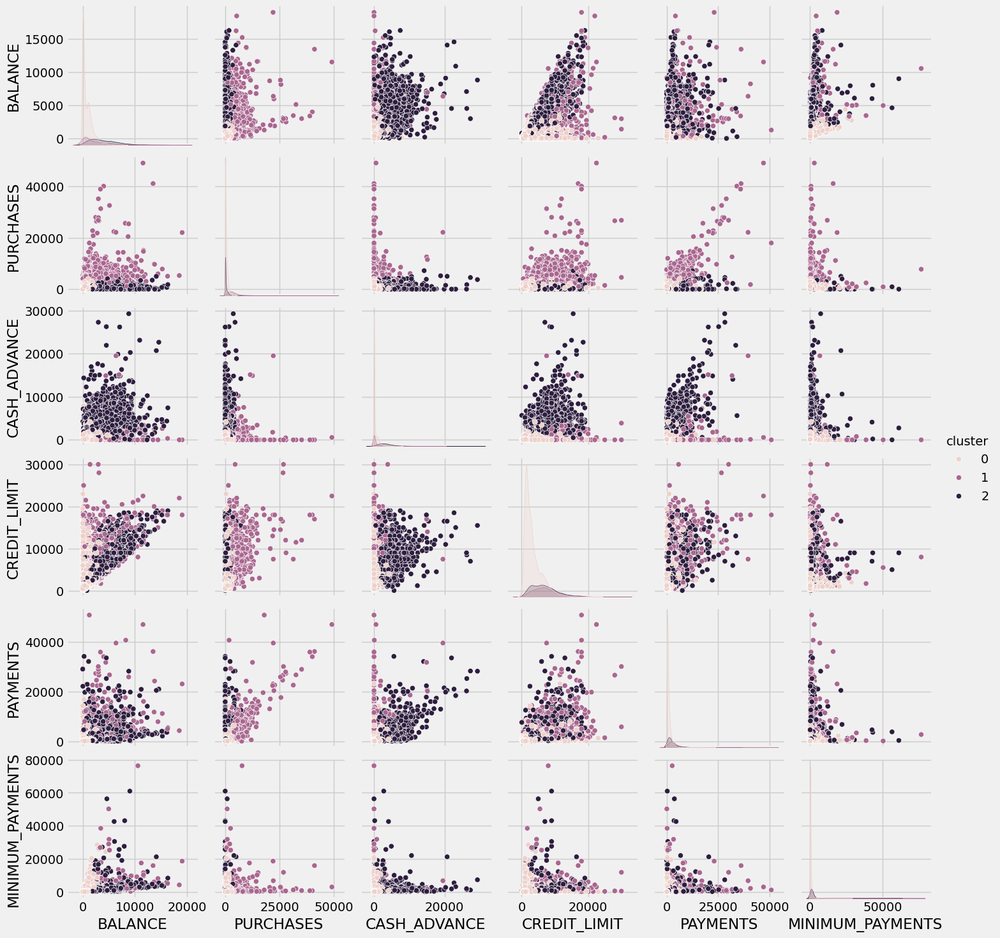

In [46]:
best_cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE","CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS","cluster"]
sns.pairplot( df_kmean[ best_cols ], hue="cluster")

## Evaluation

In [47]:
# 1. Number of clusters
print("Number of clusters found:")
print(df_kmean['cluster'].nunique())

# 2. Number of customers in each cluster
print("\nNumber of customers in each cluster:")
print(df_kmean['cluster'].value_counts().sort_index())

# 3. Mean feature values for each cluster
print("\nMean feature values for each cluster:")
display(df_kmean.groupby('cluster').mean(numeric_only=True).round(2))

# 4. Relative size of each cluster
print("\nPercentage of customers in each cluster:")
display(
    (df_kmean['cluster'].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Number of clusters found:
3

Number of customers in each cluster:
cluster
0    6115
1    1233
2    1599
Name: count, dtype: int64

Mean feature values for each cluster:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
cluster,,,,,,,,,,,,,,,,,
0,800.65,0.84,506.15,254.78,251.69,326.28,0.47,0.13,0.35,0.07,1.20,8.66,3271.08,908.62,529.45,0.16,11.48
1,2227.57,0.98,4257.71,2714.18,1544.01,459.46,0.95,0.67,0.75,0.06,1.55,56.57,7725.51,4154.41,1249.70,0.30,11.92
2,3967.79,0.96,382.03,248.65,133.46,3847.31,0.23,0.11,0.14,0.45,12.31,5.56,6660.42,2992.62,1736.32,0.03,11.35



Percentage of customers in each cluster:


,proportion
cluster,
0,68.35
1,13.78
2,17.87


In [48]:

from sklearn.metrics import silhouette_score, calinski_harabasz_score

print("Silhouette Score:",
      silhouette_score(scaled_df, labels))

print("Calinski-Harabasz Score:",
      calinski_harabasz_score(scaled_df, labels))


Silhouette Score: 0.25069358856132073
Calinski-Harabasz Score: 1624.360699180715


## 2. Gaussian Mixture Model

### A Gaussian mixture model (GMM) attempts to find a mixture of multi-dimensional Gaussian probability distributions that best model any input dataset.

**<span style="color:#682F2F;"> 1. If the model is having some hidden, not observable parameters, then we should use GMM. This is because, GMM assigns a probability to each point to belong to a certain cluster, instead of assigning a flag that the point belongs to a certain cluster as in the classical k-Means.</span>**

**<span style="color:#682F2F;">2. GMM produces non-convex clusters, which can be controlled with the variance of the distribution. In fact, k-Means is a special case of GMM, such that the probability of one point belonging to a certain cluster is 1, all other probabilities are 0, and the variance is 1, which is a reason why k-Means produces only spherical clusters.</span>**

**<span style="color:#682F2F;"> 3. GMM allows for a diverse membership of points to clusters. In kmeans, a point belongs to one and only one cluster, whereas in GMM a point belongs to each cluster to a different degree. The degree is based on the probability of the point being generated from each cluster’s (multivariate) normal distribution, with cluster center as the distribution’s mean and cluster covariance as its covariance. Depending on the task, mixed membership may be more appropriate (e.g. news articles can belong to multiple topic clusters) or not (e.g. organisms can belong to only one species). we can call the predict_proba function to return the probabilities that a data point belongs to each of the K clusters.</span>**

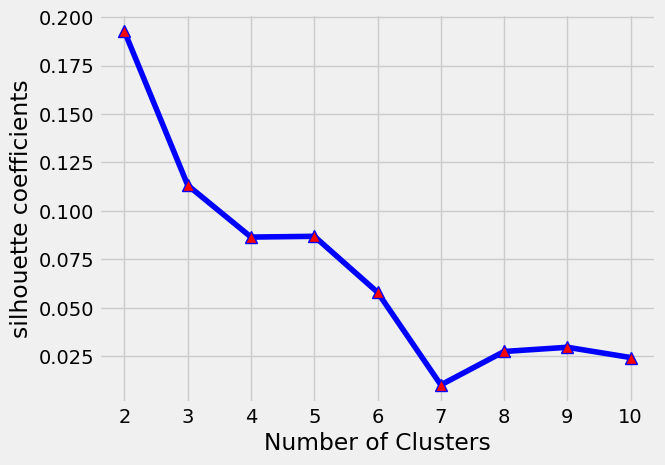

maxs silhouette 0.19259165836625086


In [49]:
from sklearn.mixture import GaussianMixture
score_gmm = []
for k in range(2,11):  #this range is optional
    gmm = GaussianMixture(n_components=k, random_state=1 )   #each gaussian in your mixture is one component
    gmm.fit(scaled_df)
    score = silhouette_score(scaled_df, gmm.predict(scaled_df), metric='euclidean',random_state=1)
    score_gmm.append(score)
plt.style.use("fivethirtyeight")
plt.plot(range(2,11), score_gmm, marker = '^', c = 'b', ms = 9, mfc = 'r')
plt.xticks(range(2,11))
plt.xlabel("Number of Clusters")
plt.ylabel("silhouette coefficients")
plt.show()
print('maxs silhouette',max(score_gmm ))

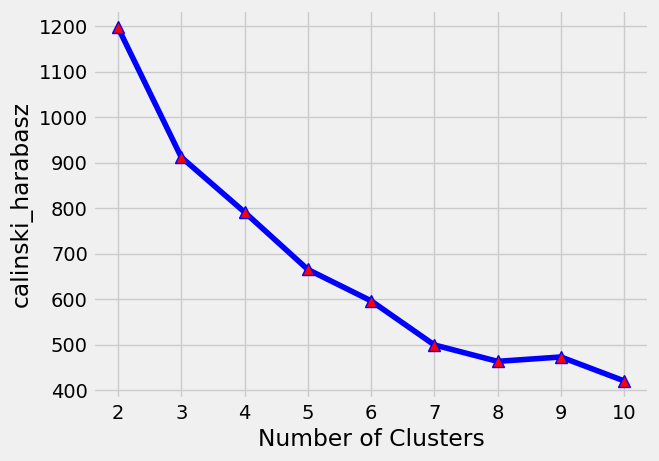

In [50]:
from sklearn import metrics
from sklearn.metrics import calinski_harabasz_score
calinski_harabaz = []
for k in range (2,11):
    gmm = GaussianMixture(n_components=k, random_state=1 )
    gmm.fit(scaled_df)
    metrics.calinski_harabasz_score(scaled_df, gmm.predict(scaled_df))
    calinski_harabaz.append(metrics.calinski_harabasz_score(scaled_df, gmm.predict(scaled_df)))
plt.style.use("fivethirtyeight")
plt.plot(range(2,11), calinski_harabaz, marker = '^', c = 'b', ms = 9, mfc = 'r')
plt.xticks(range(2,11))
plt.xlabel("Number of Clusters")
plt.ylabel("calinski_harabasz")
plt.show()

### Number of clusters = 2

In [51]:
# In gaussian method, we don't have centers, we have mean for each cluster
from sklearn.mixture import GaussianMixture
gmm = GaussianMixture(n_components=2, random_state=1 )
gmm.fit(scaled_df)
labels = gmm.predict(scaled_df)
cluster_means = pd.DataFrame(data = gmm.means_, columns = [df.columns])
cluster_means

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-0.177353,-0.181049,-0.338466,-0.276979,-0.297163,-0.064388,-0.368288,-0.431535,-0.254996,0.046761,0.009414,-0.381561,-0.247275,-0.282432,-0.170903,-0.086228,-0.113898
1,0.331459,0.338365,0.632566,0.517653,0.555373,0.120337,0.688301,0.806505,0.476567,-0.087393,-0.017593,0.713107,0.462138,0.527843,0.319405,0.161153,0.212866


In [52]:
# view real cordinates means of clusters(in gaussian we can show mean, instead center)
cluster_means = scaler.inverse_transform(cluster_means)
cluster_means = pd.DataFrame(data = cluster_means, columns = [df.columns])
cluster_means

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,1194.573467,0.834480,281.833047,132.823315,149.009732,842.571300,0.342570,0.073747,0.263104,0.144408,3.299192,5.225535,3593.023327,918.545701,445.761713,0.128543,11.365524
1,2252.491127,0.957479,2345.002852,1451.946432,893.917907,1219.371419,0.766665,0.443121,0.553879,0.117587,3.118062,32.438795,6168.365235,3241.896622,1589.418946,0.200906,11.802469


In [53]:
#adding cluster column to dataframe
df_cluster_with_gmm = pd.concat([df, pd.DataFrame({'cluster': labels})], axis = 1)
df_cluster_with_gmm

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,cluster
0,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12,0
1,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12,0
2,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12,1
3,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,312.255623,0.000000,12,1
4,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8942,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6,0
8943,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,312.255623,0.000000,6,0
8944,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6,0
8945,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6,0


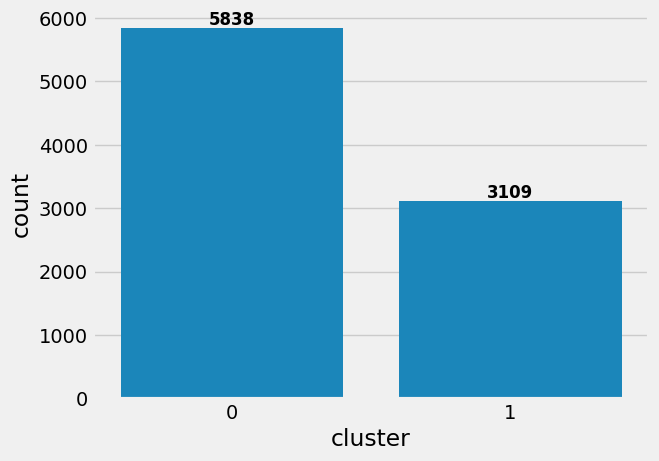

In [54]:
ax = sns.countplot(x=df_cluster_with_gmm.cluster)
ax.bar_label(ax.containers[0], fontsize=12, color='black', fontweight='bold')
plt.show()

### Data visualization

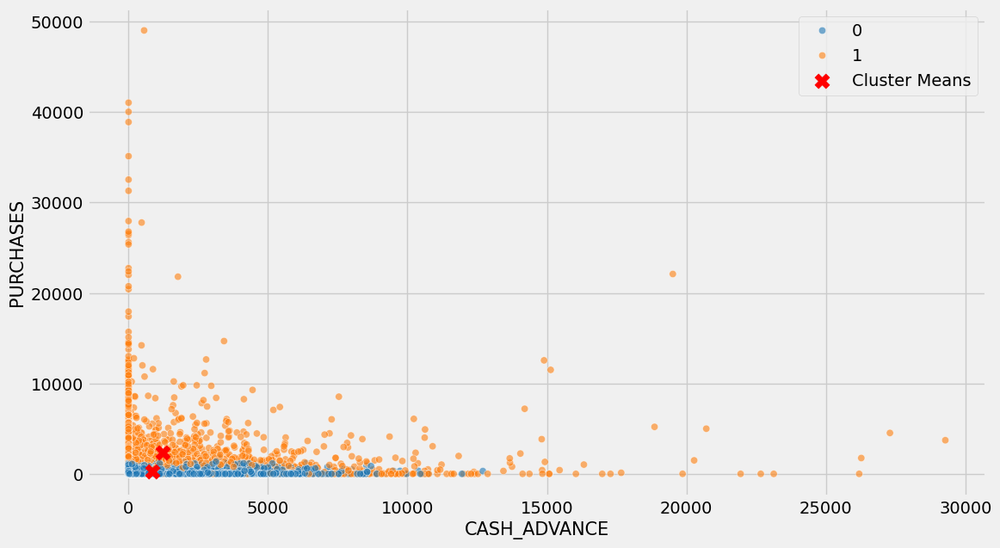

In [57]:
df_gmm = df.copy()
df_gmm['cluster'] = labels

x_col = 'CASH_ADVANCE'
y_col = 'PURCHASES'

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df_gmm,
    x=x_col,
    y=y_col,
    hue='cluster',
    palette='tab10',
    alpha=0.6
)

# Calculate the mean of each cluster in the original feature space
cluster_means = df_gmm.groupby('cluster')[[x_col, y_col]].mean()

plt.scatter(
    cluster_means[x_col],
    cluster_means[y_col],
    c='red',
    marker='X',
    s=150,
    label='Cluster Means'
)

plt.xlabel(x_col, fontsize=15)
plt.ylabel(y_col, fontsize=15)
plt.legend()
plt.show()

## Evaluation

In [58]:
print("Silhouette Score:",
      silhouette_score(scaled_df, labels))

print("Calinski-Harabasz Score:",
      calinski_harabasz_score(scaled_df, labels))

print("\nCluster distribution:")
print(df_cluster_with_gmm['cluster'].value_counts().sort_index())

print("\nCluster means:")
display(cluster_means)

Silhouette Score: 0.19259165836625086
Calinski-Harabasz Score: 1196.9493306012114

Cluster distribution:
cluster
0    5838
1    3109
Name: count, dtype: int64

Cluster means:


,CASH_ADVANCE,PURCHASES
cluster,,
0,844.998733,282.533481
1,1215.976130,2350.054960


In [59]:
print("Best k by Silhouette:",
      range(2, 11)[score_gmm.index(max(score_gmm))])

print("Best k by Calinski-Harabasz:",
      range(2, 11)[calinski_harabaz.index(max(calinski_harabaz))])

Best k by Silhouette: 2
Best k by Calinski-Harabasz: 2


## 3. Hierarical (Agglomerative Clustering)

### Hierarchical clustering is a popular method for grouping objects. It creates groups so that objects within a group are similar to each other and different from objects in other groups. Clusters are visually represented in a hierarchical tree called a dendrogram.

#### There are two main types of hierarchical clustering:

1. Agglomerative
2. Divisive

#### Between Agglomerative and Divisive clustering, Agglomerative clustering is generally the preferred method. We focus on Agglomerative clustering algorithms because they are the most popular and easiest to implement.

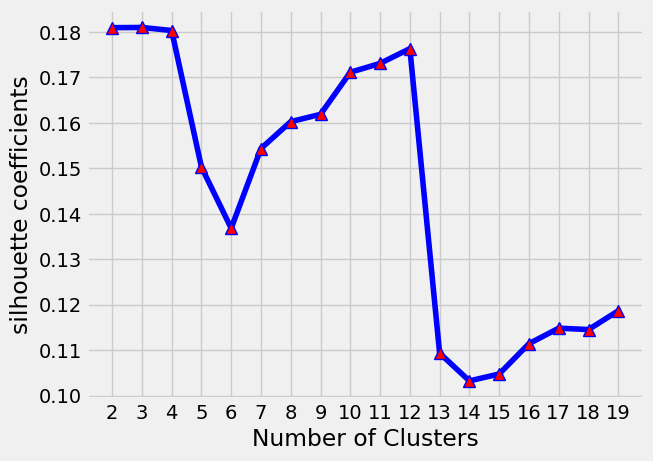

maxs silhouette 0.18100564061759292


In [60]:
from sklearn.cluster import AgglomerativeClustering
sil_Hierarch = []
for k in range(2,20):   #this range is optional
    Hierarch = AgglomerativeClustering(n_clusters = k,linkage='ward') #linkage determines which distance to use between sets of observstion.alghorithm minimize this distance
    score = silhouette_score(scaled_df, Hierarch.fit_predict(scaled_df),metric='euclidean')
    sil_Hierarch.append(score)
plt.style.use("fivethirtyeight")
plt.plot(range(2,20), sil_Hierarch, marker = '^', c = 'b', ms = 9, mfc = 'r')
plt.xticks(range(2,20))
plt.xlabel("Number of Clusters")
plt.ylabel("silhouette coefficients")
plt.show()
print('maxs silhouette',max(sil_Hierarch))

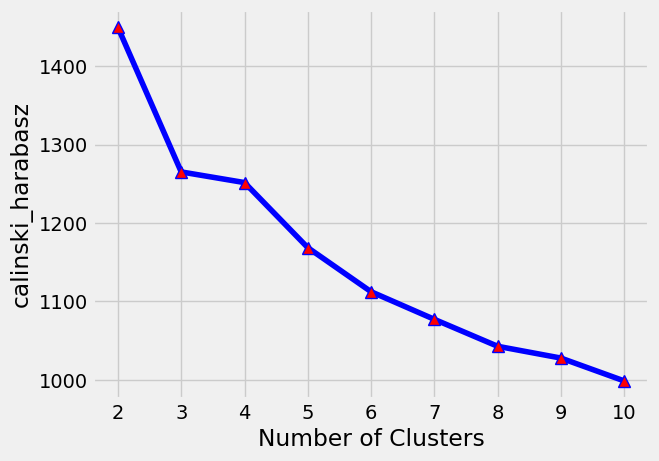

In [61]:
from sklearn.metrics import calinski_harabasz_score
calinski_harabaz = []
for k in range (2,11):
    Hierarch = AgglomerativeClustering(n_clusters = k, linkage='ward')
    score = metrics.calinski_harabasz_score(scaled_df, Hierarch.fit_predict(scaled_df))
    calinski_harabaz.append(score)
plt.style.use("fivethirtyeight")
plt.plot(range(2,11), calinski_harabaz, marker = '^', c = 'b', ms = 9, mfc = 'r')
plt.xticks(range(2,11))
plt.xlabel("Number of Clusters")
plt.ylabel("calinski_harabasz")
plt.show()

### Number of clusters = 2

In [62]:
from sklearn.cluster import AgglomerativeClustering

In [63]:
Hierarch = AgglomerativeClustering(n_clusters =2,linkage='ward')
Hierarch.fit(scaled_df)
score = silhouette_score(scaled_df, Hierarch.fit_predict(scaled_df))
print("silhouette_score",score)

silhouette_score 0.18096014887926604


In [64]:
#adding cluster column to dataframe
labels = Hierarch.labels_
df_cluster_with_Hierarch = pd.concat([df, pd.DataFrame({'cluster': labels})], axis = 1)
df_cluster_with_Hierarch

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,cluster
0,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12,0
1,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12,0
2,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12,1
3,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,312.255623,0.000000,12,0
4,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8942,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6,0
8943,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,312.255623,0.000000,6,0
8944,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6,0
8945,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6,0


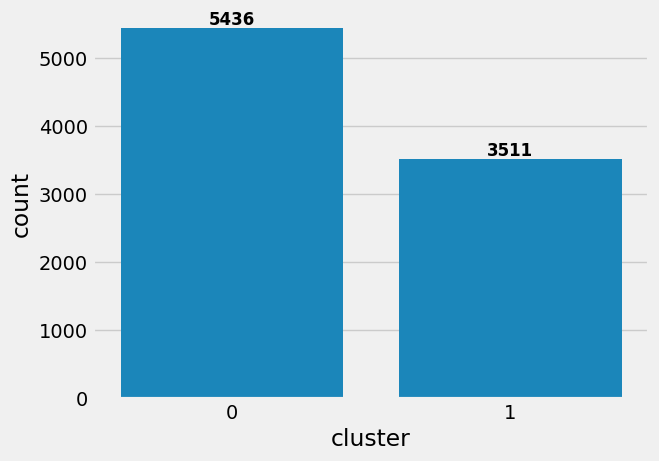

In [65]:
# counting number of clusters
ax = sns.countplot(x=df_cluster_with_Hierarch.cluster)
ax.bar_label(ax.containers[0], fontsize=12, color='black', fontweight='bold')
plt.show()

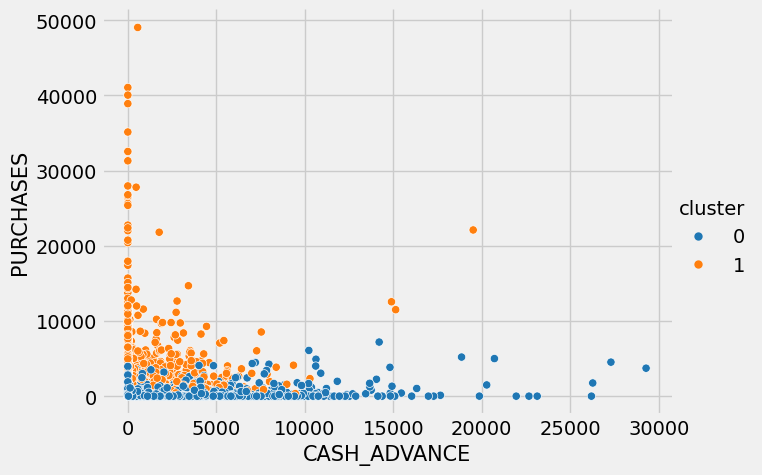

In [66]:
df_Hierarch = df.copy()
df_Hierarch['cluster'] = labels

sns.relplot(
    data=df_Hierarch,
    x='CASH_ADVANCE',
    y='PURCHASES',
    hue='cluster',
    palette='tab10',
    kind='scatter',
    aspect=11.7/8.27
)

plt.xlabel("CASH_ADVANCE", fontsize=15)
plt.ylabel("PURCHASES", fontsize=15)
plt.show()

## Evaluation

In [67]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score

sil_Hierarch = []
calinski_harabaz = []

# Evaluate cluster counts from 2 to 10
for k in range(2, 11):
    Hierarch = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels_temp = Hierarch.fit_predict(scaled_df)

    sil_Hierarch.append(silhouette_score(scaled_df, labels_temp))
    calinski_harabaz.append(
        calinski_harabasz_score(scaled_df, labels_temp)
    )

print("Best k by Silhouette:",
      range(2, 11)[sil_Hierarch.index(max(sil_Hierarch))])

print("Best k by Calinski-Harabasz:",
      range(2, 11)[calinski_harabaz.index(max(calinski_harabaz))])

# Final model: 2 clusters
Hierarch = AgglomerativeClustering(n_clusters=2, linkage='ward')
labels = Hierarch.fit_predict(scaled_df)

print("\nSilhouette Score:", silhouette_score(scaled_df, labels))
print("Calinski-Harabasz Score:",
      calinski_harabasz_score(scaled_df, labels))

df_cluster_with_Hierarch = df.copy()
df_cluster_with_Hierarch['cluster'] = labels

print("\nCluster distribution:")
print(df_cluster_with_Hierarch['cluster'].value_counts().sort_index())

print("\nCluster means:")
display(df_cluster_with_Hierarch.groupby('cluster').mean(numeric_only=True))

Best k by Silhouette: 3
Best k by Calinski-Harabasz: 2

Silhouette Score: 0.18096014887926604
Calinski-Harabasz Score: 1449.5722562442254

Cluster distribution:
cluster
0    5436
1    3511
Name: count, dtype: int64

Cluster means:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
cluster,,,,,,,,,,,,,,,,,
0,1544.047335,0.816052,322.391490,208.761422,113.923675,1274.227372,0.240813,0.084408,0.155874,0.172736,4.132082,4.199227,3962.650252,1417.006245,889.336063,0.091960,11.236203
1,1593.171242,0.972265,2051.618112,1186.942148,864.986582,508.935459,0.876814,0.385333,0.687401,0.076724,1.848761,30.986329,5308.248751,2210.473663,774.822829,0.249459,11.953859


## 4. DBSCAN

### Density-based spatial clustering of applications with noise (DBSCAN) is a clustering algorithm that defines clusters as continuous regions of high density and works well if all the clusters are dense enough and well separated by low-density regions.

**It works based on two parameters: Epsilon and Minimum Points**
* Epsilon determine a specified radius that if includes enough number of points within, we call it dense area
* minimumSamples determine the minimum number of data points we want in a neighborhood to define a cluster.

In [68]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

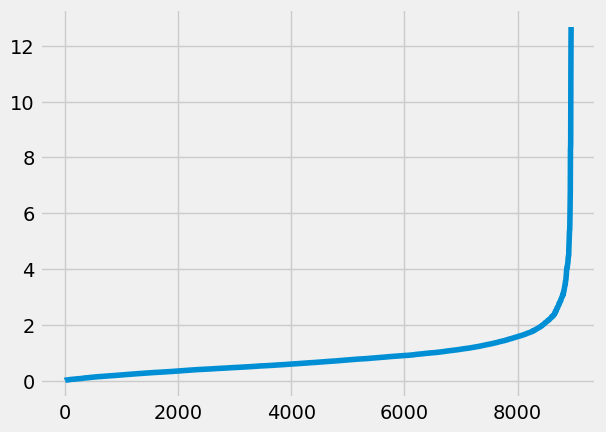

In [69]:
from sklearn.neighbors import NearestNeighbors
neigh = NearestNeighbors(n_neighbors=4)
nbrs = neigh.fit(scaled_df)
distances, indices = nbrs.kneighbors(scaled_df)
distances = np.sort(distances, axis=0)
distances = distances[:,1]
plt.plot(distances)

#### Until around 8000th variable eps is under 2. density is too much in the general data set Here we can also see

### It is difficult arbitrarily to say what values for Epsilon and minimum Samples will work the best. Therefore, I will use a 'for' loop to find ones.

In [70]:
siliuette_list_dbscan = []

for eps in np.arange(0.1,2,0.2):
    for min_sample in range(1,10):
        dbscan = DBSCAN(eps=eps, min_samples= min_sample)
        dbscan.fit(scaled_df)
        sil_score = metrics.silhouette_score(scaled_df, dbscan.labels_, metric='euclidean')
        siliuette_list_dbscan.append((eps, min_sample, sil_score, len(set(dbscan.labels_))) )

df_dbscan = pd.DataFrame(siliuette_list_dbscan, columns=['eps', 'min_samples', 'sil_score', 'number_of_clusters'])

In [71]:
df_dbscan.sort_values('sil_score', ascending=False).head()

,eps,min_samples,sil_score,number_of_clusters
85,1.9,5,0.458543,2
86,1.9,6,0.453556,2
87,1.9,7,0.447483,2
88,1.9,8,0.444152,2
89,1.9,9,0.440888,2


In [72]:
siliuette_list_dbscan = []

for eps in np.arange(0.1,3,0.2):
    for min_sample in range(1,20,4):
        dbscan = DBSCAN(eps=eps, min_samples=min_sample)
        dbscan.fit(scaled_df)
        sil_score = metrics.silhouette_score(scaled_df, dbscan.labels_, metric='euclidean')
        siliuette_list_dbscan.append((eps, min_sample, sil_score, len(set(dbscan.labels_))) )
df_dbscan = pd.DataFrame(siliuette_list_dbscan, columns=['eps', 'min_samples', 'sil_score', 'number_of_clusters'])

In [73]:
df_dbscan.sort_values('sil_score', ascending=False).tail()


,eps,min_samples,sil_score,number_of_clusters
30,1.3,1,-0.398496,1551
7,0.3,9,-0.400440,14
6,0.3,5,-0.422388,46
16,0.7,5,-0.455660,30
11,0.5,5,-0.469988,38


#### Even though, checking the silhouette score to choose the best DBSCAN metric does not give the best model for our data set. This method seems not a suitable one for our desired model even with a high silhouette score. The reason behind this is that we have a high number of variables in the same cluster itself but distribution of variables does not distributes homogenous in all clusters.

In [74]:
dbscan = DBSCAN(eps=3, min_samples=4)
dbscan.fit(scaled_df)
Labels = dbscan.labels_
Labels

array([0, 0, 0, ..., 0, 0, 0])

In [75]:
dbscan_df = pd.DataFrame(scaled_df, columns = df.columns)
dbscan_df['clusters'] = Labels
dbscan_df.head()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE,clusters
0,-0.732220,-0.249876,-0.426211,-0.356991,-0.358518,-0.477456,-0.806533,-0.678717,-0.707283,-0.675534,-0.482502,-0.511310,-0.961559,-0.532398,-0.302200,-0.525663,0.360587,0
1,0.788357,0.134026,-0.471111,-0.356991,-0.467702,2.681176,-1.221767,-0.678717,-0.916941,0.574907,0.113905,-0.591761,0.691223,0.828166,0.097723,0.234022,0.360587,0
2,0.448167,0.517929,-0.107218,0.108762,-0.467702,-0.477456,1.269632,2.673010,-0.916941,-0.675534,-0.482502,-0.109054,0.828955,-0.385830,-0.093081,-0.525663,0.360587,0
3,0.049705,-1.017680,0.234394,0.545997,-0.467702,-0.376569,-1.014151,-0.399407,-0.916941,-0.258722,-0.333400,-0.551535,0.828955,-0.602777,-0.228140,-0.525663,0.360587,0
4,-0.358606,0.517929,-0.463581,-0.347353,-0.467702,-0.477456,-1.014151,-0.399407,-0.916941,-0.675534,-0.482502,-0.551535,-0.906466,-0.366206,-0.257064,-0.525663,0.360587,0


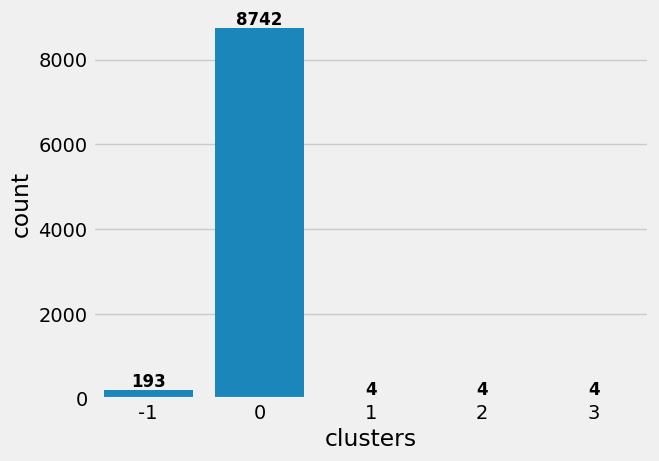

In [76]:
# counting number of clusters
ax = sns.countplot(x=dbscan_df.clusters)
ax.bar_label(ax.containers[0], fontsize=12, color='black', fontweight='bold')
plt.show()

In [132]:
sil_score = metrics.silhouette_score(scaled_df, dbscan.labels_, metric='euclidean')
sil_score

np.float64(0.842466648678264)

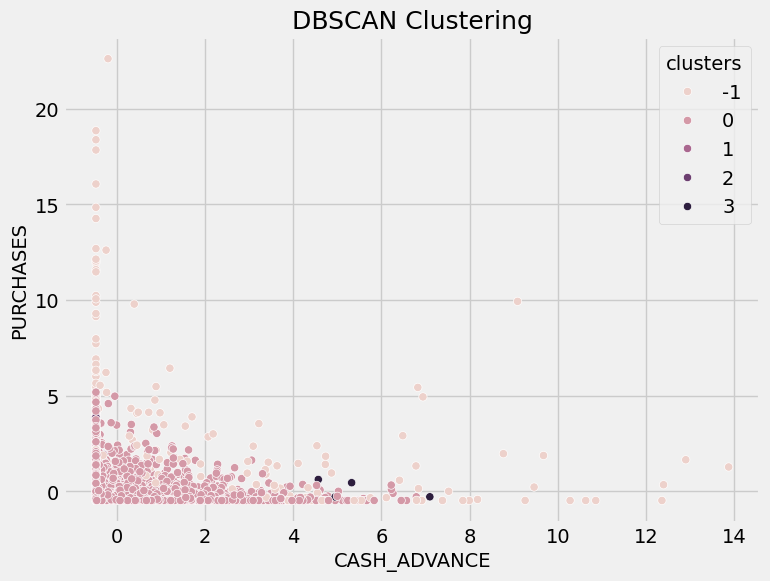

In [78]:
plt.figure(figsize=(8,6))
#plt.scatter(dbscan_df['CASH_ADVANCE'], dbscan_df['PURCHASES'], c=dbscan_df['clusters'])

sns.scatterplot(
    x='CASH_ADVANCE',
    y='PURCHASES',
    data=dbscan_df,
    hue=dbscan_df['clusters']
)

plt.title('DBSCAN Clustering',fontsize=18)
plt.xlabel('CASH_ADVANCE',fontsize=14)
plt.ylabel('PURCHASES',fontsize=14)
plt.show()

## Evaluation

In [79]:
labels = dbscan.labels_

n_clusters = len(set(labels) - {-1})
n_noise = (labels == -1).sum()

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

mask = labels != -1

if len(set(labels[mask])) >= 2:
    print("Silhouette Score (excluding noise):",
          silhouette_score(scaled_df[mask], labels[mask]))
else:
    print("Silhouette Score cannot be calculated: fewer than 2 clusters.")

Number of clusters: 4
Number of noise points: 193
Silhouette Score (excluding noise): 0.4125287962287485


In [80]:
for eps in [0.5, 1, 1.5, 2, 2.5, 3, 3.5]:
    model = DBSCAN(eps=eps, min_samples=4)
    labels = model.fit_predict(scaled_df)

    n_clusters = len(set(labels) - {-1})
    n_noise = (labels == -1).sum()

    print(f"eps={eps}: clusters={n_clusters}, noise={n_noise}")

eps=0.5: clusters=60, noise=6423
eps=1: clusters=22, noise=2943
eps=1.5: clusters=10, noise=1263
eps=2: clusters=4, noise=579
eps=2.5: clusters=4, noise=318
eps=3: clusters=4, noise=193
eps=3.5: clusters=1, noise=129


In [81]:
dbscan = DBSCAN(eps=3, min_samples=4)
labels = dbscan.fit_predict(scaled_df)

mask = labels != -1

print("Number of clusters:", len(set(labels) - {-1}))
print("Number of noise points:", (labels == -1).sum())
print("Silhouette Score (excluding noise):",
      silhouette_score(scaled_df[mask], labels[mask]))

Number of clusters: 4
Number of noise points: 193
Silhouette Score (excluding noise): 0.4125287962287485


# Dimensionality Reduction

## PCA

In [82]:
from sklearn.decomposition import PCA

In [83]:
# Obtain the principal components
pca = PCA(n_components = 2)
principal_comp = pca.fit_transform(scaled_df)
# Create a dataframe with the two components
pca_df = pd.DataFrame(data = principal_comp, columns = ['pca1', 'pca2'])
pca_df.head()

,pca1,pca2
0,-1.675093,-1.096418
1,-1.163723,2.533159
2,0.961877,-0.373514
3,-0.893124,-0.003595
4,-1.596166,-0.704667


# Models after Dimensionality Reduction

## Clustering  Algorithms

### <p style="background-color:#682F2F;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;"> 1. K-means algorithm</p>

In [84]:
kmean_set = {'init':'random', 'n_init':10, 'max_iter':300, 'random_state':1}

from sklearn.cluster import KMeans
List = []
for k in range(1, 11):   #this range is optional
    kmeans = KMeans(n_clusters=k, **kmean_set )  # ** Open dic
    kmeans.fit(pca_df)
    List.append(kmeans.inertia_)

In [85]:
print('List of interia: ', List)

List of interia:  [72628.43754800671, 49731.55437728557, 32867.34631380387, 24361.30798211484, 19281.934766711325, 16032.287118239796, 13577.855732288475, 12074.856260340599, 10684.931401434924, 9651.792307840686]


### >> The Elbow method

In [86]:
!pip install kneed

In [ ]:
from kneed import KneeLocator, DataGenerator
kl = KneeLocator(range(1, 11), List, curve = 'convex', direction = 'decreasing')
kl.elbow

plt.style.use('fivethirtyeight')
plt.plot(range(1, 11), List, marker = '^', c='b',  ms = 9, mfc = 'r')
plt.xticks(range(1, 11))
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.axvline(x=kl.elbow, color ='gray', label = 'axvline - full height', ls = '--')

plt.show()

## Model Evaluation

### >> Silhouette Coefficient
**Silhouette Coefficient or silhouette score is a metric used to calculate the goodness of a clustering technique. Its value ranges from -1 to 1.**

* 1: Means clusters are well apart from each other and clearly distinguished.

* 0: Means clusters are indifferent, or we can say that the distance between clusters is not significant.

* -1: Means clusters are assigned in the wrong way.

In [ ]:
from sklearn.metrics import silhouette_score
silhouette_coefficients = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, **kmean_set )
    kmeans.fit(pca_df)
    score = silhouette_score(pca_df, kmeans.labels_)
    silhouette_coefficients.append(score)

In [ ]:
print('silhouette_coefficients: ', silhouette_coefficients)

In [ ]:
plt.style.use('fivethirtyeight')
plt.plot(range(2, 11), silhouette_coefficients, marker = '^', c = 'b', ms = 9, mfc = 'r')
plt.xticks(range(2, 11))
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Coefficient')
plt.show()

### >> Calinski_Harabasz Coefficient
#### The Calinski-Harabasz index (CH) is one of the clustering algorithms evaluation measures. It is most commonly used to evaluate the goodness of split by a K-Means clustering algorithm for a given number of clusters. The Calinski-Harabasz index (also known as the Variance Ratio Criterion) is calculated as a ratio of the sum of inter-cluster dispersion and the sum of intra-cluster dispersion for all clusters (where the dispersion is the sum of squared distances).
#### A high CH means better clustering since observations in each cluster are closer together (more dense), while clusters themselves are further away from each other (well separated).

In [ ]:
from sklearn import metrics
from sklearn.metrics import calinski_harabasz_score

calinski_harabaz = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, **kmean_set)
    kmeans.fit(pca_df)

    score = calinski_harabasz_score(pca_df, kmeans.labels_)
    calinski_harabaz.append(score)

plt.style.use("fivethirtyeight")
plt.plot(range(2, 11), calinski_harabaz, marker='^', c='b', ms=9, mfc='r')
plt.xticks(range(2, 11))
plt.xlabel("Number of Clusters")
plt.ylabel("Calinski-Harabasz Score")
plt.show()

print('calinski_harabaz: ', calinski_harabaz)


In [ ]:
print('calinski_harabaz: ', calinski_harabaz)

## Apply the k-means

In [ ]:
#kmeans = KMeans(n_clusters=4, **kmean_set )
kmeans = KMeans(n_clusters=2, **kmean_set )
kmeans.fit(pca_df)
labels = kmeans.labels_

In [ ]:
#cluster centers (normalized centers, here ther are negative values)
cluster_centers = pd.DataFrame(data = kmeans.cluster_centers_, columns = [pca_df.columns])
cluster_centers

#### We add cluster column to dataframe

In [ ]:
df_cluster_with_kmean = pd.concat([pca_df, pd.DataFrame({'cluster': labels})], axis = 1)
df_cluster_with_kmean

### let us have a look at the group distribution of clustring

In [ ]:
#sns.countplot(x=df_cluster_with_kmean.cluster)
ax = sns.countplot(x=df_cluster_with_kmean.cluster)
ax.bar_label(ax.containers[0], fontsize=12, color='black', fontweight='bold')
plt.show()

#### most of people are grouped in cluster 1

In [ ]:
# Plot the histogram of various clusters
for i in pca_df.columns:
    plt.figure(figsize=(30,5))
    #for j in range(3):
    for j in range(2):
        plt.subplot(1,3,j+1)
        cluster = df_cluster_with_kmean[df_cluster_with_kmean['cluster'] == j]
        cluster[i].hist(bins = 20)
        plt.title('{}  \n\nCluster {}'.format(i,j), color='black', fontsize = 15, y=1.03)

plt.show()

## visualizing clusters on original data

In [ ]:
df_kmean = pca_df.copy()
df_kmean['cluster'] = labels

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_kmean,
    x='pca1',
    y='pca2',
    hue='cluster',
    palette='tab10',
    alpha=0.6
)

plt.xlabel('PCA 1', fontsize=15)
plt.ylabel('PCA 2', fontsize=15)
plt.title('K-Means Clusters on PCA-Reduced Data')
plt.show()

## Evaluation

In [ ]:
# 1. Number of clusters
print("Number of clusters found:")
print(df_kmean['cluster'].nunique())

# 2. Number of customers in each cluster
print("\nNumber of customers in each cluster:")
print(df_kmean['cluster'].value_counts().sort_index())

# 3. Mean feature values for each cluster
print("\nMean feature values for each cluster:")
display(df_kmean.groupby('cluster').mean(numeric_only=True).round(2))

# 4. Relative size of each cluster
print("\nPercentage of customers in each cluster:")
display(
    (df_kmean['cluster'].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

In [ ]:

from sklearn.metrics import silhouette_score, calinski_harabasz_score

print("Silhouette Score:",
      silhouette_score(pca_df, labels))

print("Calinski-Harabasz Score:",
      calinski_harabasz_score(pca_df, labels))


## <p style="background-color:#682F2F;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;"> 2. Gaussian Mixture Model</p>

In [ ]:
from sklearn.mixture import GaussianMixture

score_gmm = []

for k in range(2, 11):
    gmm = GaussianMixture(n_components=k, random_state=1)
    gmm.fit(pca_df)

    labels = gmm.predict(pca_df)
    score = silhouette_score(pca_df, labels)

    score_gmm.append(score)

plt.style.use("fivethirtyeight")
plt.plot(range(2, 11), score_gmm, marker='^', c='b', ms=9, mfc='r')
plt.xticks(range(2, 11))
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Coefficient")
plt.show()

print('Max Silhouette:', max(score_gmm))

In [ ]:
from sklearn import metrics
from sklearn.metrics import calinski_harabasz_score
calinski_harabaz = []
for k in range (2,11):
    gmm = GaussianMixture(n_components=k, random_state=1 )
    gmm.fit(pca_df)
    metrics.calinski_harabasz_score(pca_df, gmm.predict(pca_df))
    calinski_harabaz.append(metrics.calinski_harabasz_score(pca_df, gmm.predict(pca_df)))
plt.style.use("fivethirtyeight")
plt.plot(range(2,11), calinski_harabaz, marker = '^', c = 'b', ms = 9, mfc = 'r')
plt.xticks(range(2,11))
plt.xlabel("Number of Clusters")
plt.ylabel("calinski_harabasz")
plt.show()

### Number of clusters = 8

In [ ]:
# In gaussian method, we don't have centers, we have mean for each cluster
from sklearn.mixture import GaussianMixture
gmm = GaussianMixture(n_components=8, random_state=1 )
gmm.fit(pca_df)
labels = gmm.predict(pca_df)
cluster_means = pd.DataFrame(data = gmm.means_, columns = [pca_df.columns])
cluster_means

In [ ]:
#adding cluster column to dataframe
df_cluster_with_gmm = pd.concat([pca_df, pd.DataFrame({'cluster': labels})], axis = 1)
df_cluster_with_gmm

In [ ]:
ax = sns.countplot(x=df_cluster_with_gmm.cluster)
ax.bar_label(ax.containers[0], fontsize=12, color='black', fontweight='bold')
plt.show()

### Data visualization

In [ ]:
df_gmm = pca_df.copy()
df_gmm['cluster'] = labels

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_gmm,
    x='pca1',
    y='pca2',
    hue='cluster',
    palette='tab10',
    alpha=0.6
)

plt.xlabel('PCA 1', fontsize=15)
plt.ylabel('PCA 2', fontsize=15)
plt.title('GMM Clusters on PCA-Reduced Data')
plt.show()

## Evaluation

In [ ]:
print("Silhouette Score:",
      silhouette_score(pca_df, labels))

print("Calinski-Harabasz Score:",
      calinski_harabasz_score(pca_df, labels))

print("\nCluster distribution:")
print(df_cluster_with_gmm['cluster'].value_counts().sort_index())

print("\nCluster means:")
display(cluster_means)

In [ ]:
print("Best k by Silhouette:",
      range(2, 11)[score_gmm.index(max(score_gmm))])

print("Best k by Calinski-Harabasz:",
      range(2, 11)[calinski_harabaz.index(max(calinski_harabaz))])

## 3. Hierarical (Agglomerative Clustering)

In [ ]:
from sklearn.cluster import AgglomerativeClustering
sil_Hierarch = []
for k in range(2,20):   #this range is optional
    Hierarch = AgglomerativeClustering(n_clusters = k,linkage='ward') #linkage determines which distance to use between sets of observstion.alghorithm minimize this distance
    score = silhouette_score(pca_df, Hierarch.fit_predict(pca_df),metric='euclidean')
    sil_Hierarch.append(score)
plt.style.use("fivethirtyeight")
plt.plot(range(2,20), sil_Hierarch, marker = '^', c = 'b', ms = 9, mfc = 'r')
plt.xticks(range(2,20))
plt.xlabel("Number of Clusters")
plt.ylabel("silhouette coefficients")
plt.show()
print('maxs silhouette',max(sil_Hierarch))

In [ ]:
from sklearn.metrics import calinski_harabasz_score
calinski_harabaz = []
for k in range (2,11):
    Hierarch = AgglomerativeClustering(n_clusters = k, linkage='ward')
    score = metrics.calinski_harabasz_score(pca_df, Hierarch.fit_predict(pca_df))
    calinski_harabaz.append(score)
plt.style.use("fivethirtyeight")
plt.plot(range(2,11), calinski_harabaz, marker = '^', c = 'b', ms = 9, mfc = 'r')
plt.xticks(range(2,11))
plt.xlabel("Number of Clusters")
plt.ylabel("calinski_harabasz")
plt.show()

### Number of clusters = 2

In [ ]:
from sklearn.cluster import AgglomerativeClustering

In [ ]:
Hierarch = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

labels = Hierarch.fit_predict(pca_df)

score = silhouette_score(pca_df, labels)
print("Silhouette Score:", score)

In [ ]:
#adding cluster column to dataframe
labels = Hierarch.labels_
df_cluster_with_Hierarch = pd.concat([pca_df, pd.DataFrame({'cluster': labels})], axis = 1)
df_cluster_with_Hierarch

In [ ]:
# counting number of clusters
ax = sns.countplot(x=df_cluster_with_Hierarch.cluster)
ax.bar_label(ax.containers[0], fontsize=12, color='black', fontweight='bold')
plt.show()

In [ ]:
df_Hierarch = pca_df.copy()
df_Hierarch['cluster'] = labels

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_Hierarch,
    x='pca1',
    y='pca2',
    hue='cluster',
    palette='tab10',
    alpha=0.6
)

plt.xlabel('PCA 1', fontsize=15)
plt.ylabel('PCA 2', fontsize=15)
plt.title('Agglomerative Clusters on PCA-Reduced Data')
plt.show()

## Evaluation

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score

sil_Hierarch = []
calinski_harabaz = []

# Evaluate cluster counts from 2 to 10
for k in range(2, 11):
    Hierarch = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels_temp = Hierarch.fit_predict(pca_df)

    sil_Hierarch.append(silhouette_score(pca_df, labels_temp))
    calinski_harabaz.append(
        calinski_harabasz_score(pca_df, labels_temp)
    )

print("Best k by Silhouette:",
      range(2, 11)[sil_Hierarch.index(max(sil_Hierarch))])

print("Best k by Calinski-Harabasz:",
      range(2, 11)[calinski_harabaz.index(max(calinski_harabaz))])

# Final model: 2 clusters
Hierarch = AgglomerativeClustering(n_clusters=2, linkage='ward')
labels = Hierarch.fit_predict(pca_df)

print("\nSilhouette Score:", silhouette_score(pca_df, labels))
print("Calinski-Harabasz Score:",
      calinski_harabasz_score(pca_df, labels))

df_cluster_with_Hierarch = pca_df.copy()
df_cluster_with_Hierarch['cluster'] = labels

print("\nCluster distribution:")
print(df_cluster_with_Hierarch['cluster'].value_counts().sort_index())

print("\nCluster means:")
display(df_cluster_with_Hierarch.groupby('cluster').mean(numeric_only=True))

## <p style="background-color:#682F2F;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;"> 4. DBSCAN</p>

In [ ]:
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

In [ ]:
from sklearn.neighbors import NearestNeighbors
neigh = NearestNeighbors(n_neighbors=4)
nbrs = neigh.fit(pca_df)
distances, indices = nbrs.kneighbors(pca_df)
distances = np.sort(distances, axis=0)
distances = distances[:,1]
plt.plot(distances)

In [ ]:
siliuette_list_dbscan = []

for eps in np.arange(0.1,2,0.2):
    for min_sample in range(1,10):
        dbscan = DBSCAN(eps=eps, min_samples= min_sample)
        dbscan.fit(pca_df)
        sil_score = metrics.silhouette_score(pca_df, dbscan.labels_, metric='euclidean')
        siliuette_list_dbscan.append((eps, min_sample, sil_score, len(set(dbscan.labels_))) )

df_dbscan = pd.DataFrame(siliuette_list_dbscan, columns=['eps', 'min_samples', 'sil_score', 'number_of_clusters'])

In [ ]:
df_dbscan.sort_values('sil_score', ascending=False).head()

In [121]:
siliuette_list_dbscan = []

for eps in np.arange(0.1,3,0.2):
    for min_sample in range(1,20,4):
        dbscan = DBSCAN(eps=eps, min_samples=min_sample)
        dbscan.fit(pca_df)
        sil_score = metrics.silhouette_score(pca_df, dbscan.labels_, metric='euclidean')
        siliuette_list_dbscan.append((eps, min_sample, sil_score, len(set(dbscan.labels_))) )
df_dbscan = pd.DataFrame(siliuette_list_dbscan, columns=['eps', 'min_samples', 'sil_score', 'number_of_clusters'])

In [122]:
df_dbscan.sort_values('sil_score', ascending=False).tail()


,eps,min_samples,sil_score,number_of_clusters
1,0.1,5,-0.421842,74
0,0.1,1,-0.439846,892
4,0.1,17,-0.450936,14
3,0.1,13,-0.468453,20
2,0.1,9,-0.480937,36


In [123]:
dbscan = DBSCAN(eps=3.5, min_samples=4)
dbscan.fit(pca_df)
Labels = dbscan.labels_
Labels

array([0, 0, 0, ..., 0, 0, 0])

In [124]:
dbscan_df = pd.DataFrame(pca_df, columns = pca_df.columns)
dbscan_df['clusters'] = Labels
dbscan_df.head()

,pca1,pca2,clusters
0,-1.675093,-1.096418,0
1,-1.163723,2.533159,0
2,0.961877,-0.373514,0
3,-0.893124,-0.003595,0
4,-1.596166,-0.704667,0


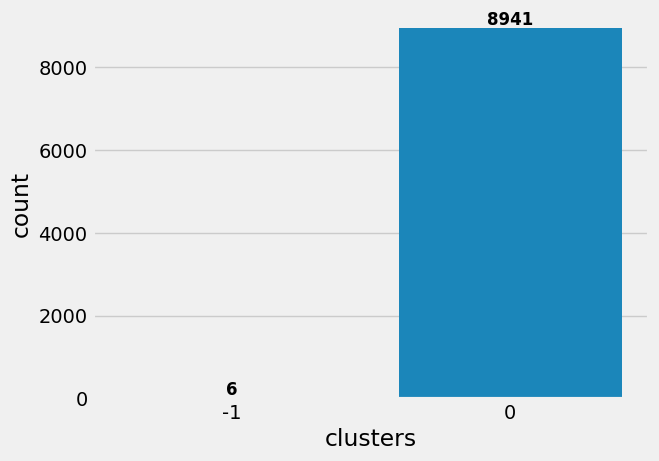

In [125]:
# counting number of clusters
ax = sns.countplot(x=dbscan_df.clusters)
ax.bar_label(ax.containers[0], fontsize=12, color='black', fontweight='bold')
plt.show()

In [126]:
sil_score = metrics.silhouette_score(pca_df, dbscan.labels_, metric='euclidean')
sil_score

np.float64(0.8732957762063072)

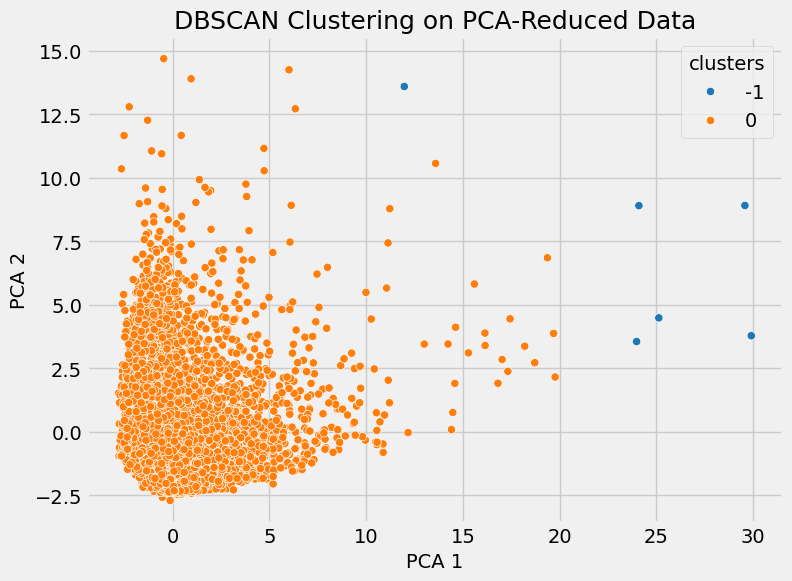

In [127]:
dbscan_df = pca_df.copy()
dbscan_df['clusters'] = Labels

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=dbscan_df,
    x='pca1',
    y='pca2',
    hue='clusters',
    palette='tab10'
)

plt.title('DBSCAN Clustering on PCA-Reduced Data', fontsize=18)
plt.xlabel('PCA 1', fontsize=14)
plt.ylabel('PCA 2', fontsize=14)
plt.show()

## Evaluation

In [128]:
labels = dbscan.labels_

n_clusters = len(set(labels) - {-1})
n_noise = (labels == -1).sum()

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

mask = labels != -1

if len(set(labels[mask])) >= 2:
    print("Silhouette Score (excluding noise):",
          silhouette_score(pca_df[mask], labels[mask]))
else:
    print("Silhouette Score cannot be calculated: fewer than 2 clusters.")

Number of clusters: 1
Number of noise points: 6
Silhouette Score cannot be calculated: fewer than 2 clusters.


In [129]:
for eps in [0.5, 1, 1.5, 2, 2.5, 3, 3.5]:
    model = DBSCAN(eps=eps, min_samples=4)
    labels = model.fit_predict(pca_df)

    n_clusters = len(set(labels) - {-1})
    n_noise = (labels == -1).sum()

    print(f"eps={eps}: clusters={n_clusters}, noise={n_noise}")

eps=0.5: clusters=8, noise=98
eps=1: clusters=1, noise=52
eps=1.5: clusters=2, noise=24
eps=2: clusters=2, noise=13
eps=2.5: clusters=1, noise=10
eps=3: clusters=1, noise=7
eps=3.5: clusters=1, noise=6


In [130]:
dbscan = DBSCAN(eps=3, min_samples=4)
labels = dbscan.fit_predict(pca_df)

mask = labels != -1

print("Number of clusters:", len(set(labels) - {-1}))
print("Number of noise points:", (labels == -1).sum())
#print("Silhouette Score (excluding noise):",     silhouette_score(pca_df[mask], labels[mask]))

Number of clusters: 1
Number of noise points: 7


In [133]:
dbscan = DBSCAN(eps=3.5, min_samples=4)
Labels = dbscan.fit_predict(pca_df)

n_clusters = len(set(Labels) - {-1})
n_noise = list(Labels).count(-1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)


mask = Labels != -1
valid_labels = Labels[mask]

if len(set(valid_labels)) >= 2:
    score = silhouette_score(
        pca_df.iloc[mask],
        valid_labels
    )
    print("Silhouette Score:", score)
else:
    print("Silhouette Score: Not comutable. less than 2 clusters !!!")

Number of clusters: 1
Number of noise points: 6
Silhouette Score: Not comutable. less than 2 clusters !!!


# Conclusion

## Comparison of Clustering Models Before and After PCA

| Model | PCA Applied | Number of Clusters | Silhouette Score | Calinski–Harabasz Score |
|---|---|---:|---:|---:|
| K-Means | No | 3 | 0.251 | 1624.36 |
| GMM | No | 2 | 0.193 | 1196.95 |
| Agglomerative Clustering | No | 2 | 0.181 | 1449.57 |
| DBSCAN (`eps=3`) | No | 4 | 0.413* | Not calculated |
| K-Means | Yes | 2 | 0.461 | 4118.43 |
| GMM | Yes | 8 | 0.376 | 4438.85 |
| Agglomerative Clustering | Yes | 2 | 0.385 | 3249.11 |
| DBSCAN (`eps=3.5`) | Yes | 1 | N/A | Not calculated |

**Note:** The Silhouette Score for DBSCAN before PCA was calculated after excluding noise points, so it is not directly comparable with scores calculated using all samples. After PCA, DBSCAN identified only one cluster and six noise points; therefore, its Silhouette Score could not be calculated.

## Conclusion

In this project, four clustering algorithms—K-Means, Gaussian Mixture Model (GMM), Agglomerative Clustering, and DBSCAN—were applied to customer segmentation before and after dimensionality reduction using PCA.

Before PCA, K-Means with three clusters achieved a Silhouette Score of 0.251 and a Calinski–Harabasz Score of 1624.36. Among K-Means, GMM, and Agglomerative Clustering, K-Means achieved the highest Silhouette Score, while GMM and Agglomerative Clustering produced lower scores. DBSCAN achieved a Silhouette Score of 0.413 after excluding noise points; however, this score is not directly comparable with the other models because it was calculated on a subset of the data.

After reducing the feature space to two principal components, K-Means with two clusters achieved a Silhouette Score of 0.461, while GMM with eight clusters obtained the highest Calinski–Harabasz Score of 4438.85. Agglomerative Clustering with two clusters achieved a Silhouette Score of 0.385 and a Calinski–Harabasz Score of 3249.11.

After PCA, DBSCAN identified only one cluster and six noise points. Since a valid Silhouette Score requires at least two clusters, this score could not be calculated.

Overall, PCA improved both evaluation scores for K-Means, GMM, and Agglomerative Clustering in this experiment. However, the best-performing algorithm depends on the evaluation metric and the resulting cluster structure. Therefore, evaluation scores should be considered alongside cluster distributions and visualizations when interpreting the resulting customer segments.